In [4]:
# If running in Colab, uncomment the next line to ensure the right TF version.
#%pip install -q --upgrade pip
#%pip install -q tensorflow==2.15.*
# ML extras
#%pip install -q scikit-image xgboost joblib

import os, sys, math, random, shutil, glob, time, itertools, json, gc, pathlib
from pathlib import Path
from typing import Tuple, List, Dict

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, classification_report)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision

# Image processing / features
from skimage import io, color, transform, feature, exposure
from skimage.feature import local_binary_pattern
from skimage.color import rgb2gray
from skimage.feature import hog # Import hog

from joblib import Parallel, delayed # Import Parallel and delayed

print("TensorFlow:", tf.__version__)
print("TF GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.18.0
TF GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [5]:

#from google.colab import drive
#drive.mount('/content/drive')

# ==== EDIT THIS: set to your dataset folder =====
# Expected structure:
#   /content/drive/MyDrive/retina_dataset/
#       glaucoma/  (3000 images)
#       normal/    (3000 images)
DATASET_DIR = "/kaggle/input/glaucomadataset/Glaucoma_Dataset2"

# Where to save outputs (models, plots, csvs)
OUTPUT_DIR = "glaucoma_outputs_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)


In [6]:
import glob

# Automatically reconstruct the 'df' DataFrame from the DATASET_DIR structure
CLASSES = ['normal', 'glaucoma']

image_records = []
for class_idx, class_name in enumerate(CLASSES):
    class_folder = os.path.join(DATASET_DIR, class_name)
    filepaths = glob.glob(os.path.join(class_folder, "*"))
    print(f"Found {len(filepaths)} images for class: {class_name}")
    for fp in filepaths:
        image_records.append({
            "filepath": fp,
            "class_name": class_name,
            "label": class_idx
        })

df = pd.DataFrame(image_records)
print("Total dataset shape:", df.shape)
print(df['class_name'].value_counts())


Found 3000 images for class: normal
Found 3000 images for class: glaucoma
Total dataset shape: (6000, 3)
class_name
normal      3000
glaucoma    3000
Name: count, dtype: int64


In [7]:

train_df, temp_df = train_test_split(
    df, test_size=0.2, stratify=df['label'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)

print("Train:", train_df.shape, train_df['class_name'].value_counts().to_dict())
print("Val:  ", val_df.shape, val_df['class_name'].value_counts().to_dict())
print("Test: ", test_df.shape, test_df['class_name'].value_counts().to_dict())

train_df.to_csv(os.path.join(OUTPUT_DIR, "train_paths.csv"), index=False)
val_df.to_csv(os.path.join(OUTPUT_DIR, "val_paths.csv"), index=False)
test_df.to_csv(os.path.join(OUTPUT_DIR, "test_paths.csv"), index=False)


Train: (4800, 3) {'normal': 2400, 'glaucoma': 2400}
Val:   (600, 3) {'glaucoma': 300, 'normal': 300}
Test:  (600, 3) {'glaucoma': 300, 'normal': 300}


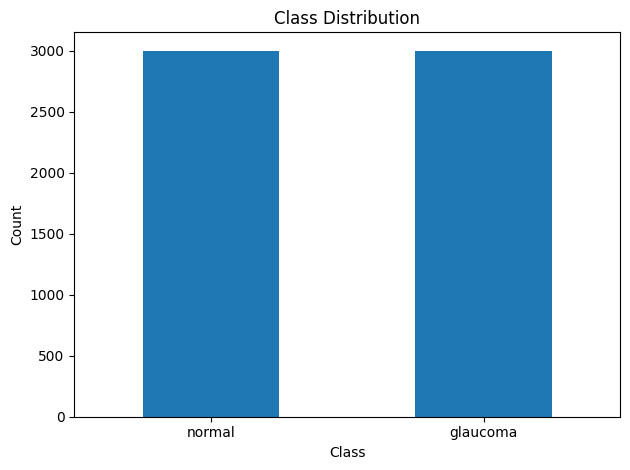

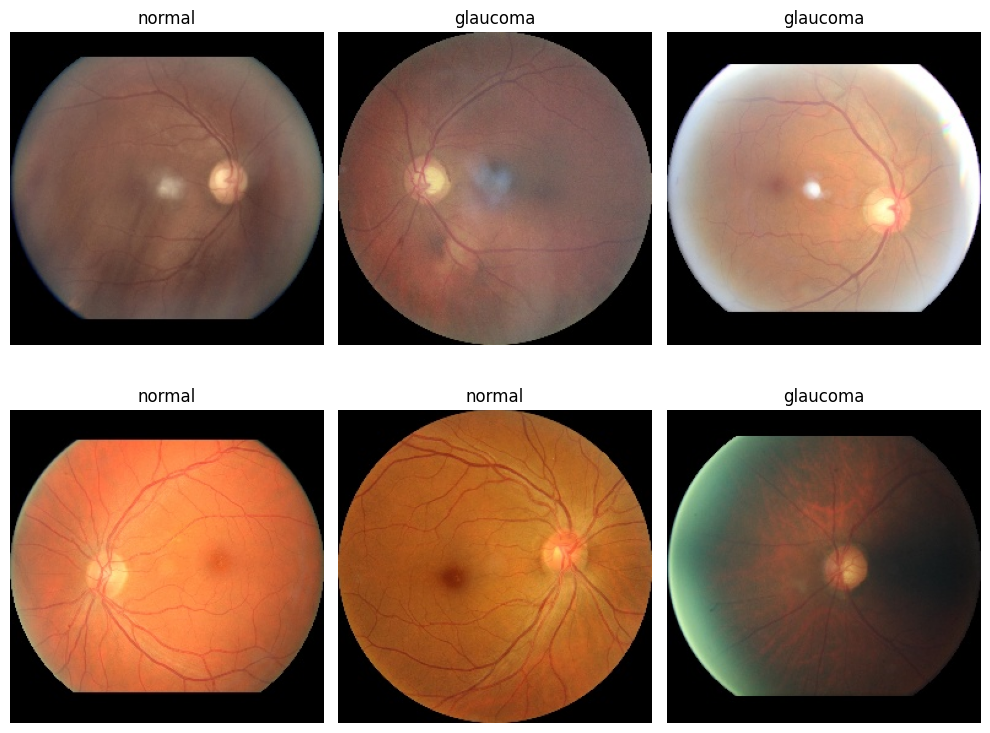

In [8]:

# Plot class counts
counts = df['class_name'].value_counts()
plt.figure()
counts.plot(kind='bar', rot=0)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Show a few random samples
def show_samples(df_sample, n=6):
    df_s = df_sample.sample(n=n, random_state=SEED)
    ncols = 3
    nrows = int(math.ceil(n / ncols))
    plt.figure(figsize=(10, 4*nrows))
    for i,(fp,cls) in enumerate(zip(df_s['filepath'].values, df_s['class_name'].values)):
        img = io.imread(fp)
        plt.subplot(nrows, ncols, i+1)
        plt.imshow(img)
        plt.title(cls)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_samples(train_df, n=6)


In [9]:

AUTOTUNE = tf.data.AUTOTUNE

def decode_img(path, img_size):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [img_size, img_size])
    return img

def make_ds(paths, labels, img_size, batch_size=32, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    def _load(path, label):
        img = decode_img(path, img_size)
        if augment:
            img = data_augment(img)
        return img, tf.one_hot(label, depth=2)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_load, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

# Keras preprocessing augment
data_augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def prepare_tf_datasets(img_size, batch_size=32):
    tr_paths, tr_labels = train_df['filepath'].values, train_df['label'].values
    va_paths, va_labels = val_df['filepath'].values, val_df['label'].values
    te_paths, te_labels = test_df['filepath'].values, test_df['label'].values

    train_ds = make_ds(tr_paths, tr_labels, img_size, batch_size, augment=True, shuffle=True)
    val_ds   = make_ds(va_paths, va_labels, img_size, batch_size, augment=False, shuffle=False)
    test_ds  = make_ds(te_paths, te_labels, img_size, batch_size, augment=False, shuffle=False)
    return train_ds, val_ds, test_ds


I0000 00:00:1792057113.739259      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792057113.742036      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [10]:

# Enable mixed precision if supported (speeds up on modern GPUs)
try:
    mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision enabled.")
except Exception as e:
    print("Mixed precision not enabled:", e)

def make_callbacks(run_name):
    ckpt_path = os.path.join(OUTPUT_DIR, f"{run_name}.keras")
    callbacks = [
        keras.callbacks.ModelCheckpoint(ckpt_path, save_best_only=True, monitor="val_auc", mode="max", verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3, verbose=1, min_lr=1e-6),
        keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, f"{run_name}_history.csv"))
    ]
    return callbacks


Mixed precision enabled.


In [11]:
METRICS = [
    keras.metrics.AUC(name='auc'),
    keras.metrics.BinaryAccuracy(name='accuracy'),
    keras.metrics.Precision(name='precision'),
    keras.metrics.Recall(name='recall'),
]

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve, classification_report

def compile_train_eval(model, train_ds, val_ds, test_ds,
                       run_name="Model", epochs_warmup=3, epochs_finetune=5,
                       lr=1e-3, lr_finetune=1e-4):

    # -------------------
    # Warm-up training (head only)
    # -------------------
    print(f"\n--- Starting Warm-up for {run_name} ---")
    model.trainable = False # Freeze the base
    for layer in model.layers:
        if "dense" in layer.name or "predictions" in layer.name: # Unfreeze dense/output layers
             layer.trainable = True

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=METRICS # Use defined METRICS
    )
    hist_warmup = model.fit(train_ds, validation_data=val_ds, epochs=epochs_warmup, callbacks=make_callbacks(f"{run_name}_warmup"))

    # -------------------
    # Fine-tuning (unfreeze backbone)
    # -------------------
    print(f"\n--- Starting Fine-tuning for {run_name} ---")
    model.trainable = True # Unfreeze the whole model
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr_finetune),
        loss="categorical_crossentropy",
        metrics=METRICS # Use defined METRICS
    )
    hist_finetune = model.fit(train_ds, validation_data=val_ds, epochs=epochs_finetune, callbacks=make_callbacks(f"{run_name}_finetune"))

    # -------------------
    # Evaluate
    # -------------------
    def collect_preds(ds):
        y_true, y_prob = [], []
        for x,y in ds:
            p = model.predict(x, verbose=0).squeeze()
            # Ensure p is a numpy array for consistent handling
            if isinstance(p, tf.Tensor):
                p = p.numpy()

            if p.ndim > 1: # Handle case where predict returns multiple columns (softmax)
                y_prob.extend(p[:, 1].tolist()) # Probability of the positive class (class 1)
            else: # Handle case where predict returns single column (sigmoid)
                 y_prob.extend(p.tolist())

            y_true.extend(tf.argmax(y, axis=1).numpy().tolist())

        y_prob = np.array(y_prob)
        y_pred = (y_prob >= 0.5).astype(int) # Threshold at 0.5 for binary prediction
        return np.array(y_true), y_pred, y_prob

    print(f"\n--- Evaluating {run_name} on Test Set ---")
    y_true, y_pred, y_prob = collect_preds(test_ds)

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    auc  = roc_auc_score(y_true, y_prob)

    cm = confusion_matrix(y_true, y_pred)
    print("Test Metrics: acc={:.4f}, prec={:.4f}, rec={:.4f}, f1={:.4f}, auc={:.4f}".format(acc,prec,rec,f1,auc))
    # Print confusion matrix components
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        print(f"Confusion Matrix (TN, FP, FN, TP): {tn}, {fp}, {fn}, {tp}")
    else:
        print("Confusion Matrix:\n", cm)


    # Save metrics
    metrics_row = pd.DataFrame([{
        "run_name": run_name,
        "model": model.name,
        "acc": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc,
        "tp": int(cm[1,1]) if cm.shape == (2,2) else None,
        "tn": int(cm[0,0]) if cm.shape == (2,2) else None,
        "fp": int(cm[0,1]) if cm.shape == (2,2) else None,
        "fn": int(cm[1,0]) if cm.shape == (2,2) else None
    }])
    csv_path = os.path.join(OUTPUT_DIR, "dl_metrics.csv")
    if os.path.exists(csv_path):
        old = pd.read_csv(csv_path)
        # Avoid adding duplicate rows for the same run_name
        old = old[old['run_name'] != run_name]
        out = pd.concat([old, metrics_row], ignore_index=True)
    else:
        out = metrics_row
    out.to_csv(csv_path, index=False)

    # Plot ROC
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0,1],[0,1],'--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC: {run_name}")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{run_name}_roc.png"))
    plt.show()

    # Confusion matrix plot
    plt.figure()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues) # Use Blues colormap
    plt.title(f"Confusion Matrix: {run_name}")
    plt.xlabel("Predicted label") # Add axis labels
    plt.ylabel("True label")
    tick_marks = np.arange(len(CLASSES))
    plt.xticks(tick_marks, CLASSES) # Add class labels to ticks
    plt.yticks(tick_marks, CLASSES)
    # Add text annotations
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{run_name}_cm.png"))
    plt.show()

    # Classification report
    report = classification_report(y_true, y_pred, target_names=CLASSES, digits=4)
    with open(os.path.join(OUTPUT_DIR, f"{run_name}_classification_report.txt"), "w") as f:
        f.write(report)
    print(report)

    return {"acc":acc, "precision":prec, "recall":rec, "f1":f1, "auc":auc}

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Starting Warm-up for EffNetB3 ---
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")
I0000 00:00:1792057128.077436     109 service.cc:148] XLA service 0x7be008215060 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792057128.078379     109 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1792057128.078489     109 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1792057129.944601     109 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/150 ━━━━━━━━━━━━━━━━━━━━ 8s 59ms/step - accuracy: 0.3993 - auc: 0.4178 - loss: 0.7207 - precision: 0.3993 - recall: 0.3993  

I0000 00:00:1792057148.554240     109 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.4840 - auc: 0.4788 - loss: 0.7055 - precision: 0.4840 - recall: 0.4840
Epoch 1: val_auc improved from -inf to 0.50908, saving model to glaucoma_outputs_final/EffNetB3_warmup.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 85s 373ms/step - accuracy: 0.4840 - auc: 0.4788 - loss: 0.7054 - precision: 0.4840 - recall: 0.4840 - val_accuracy: 0.5000 - val_auc: 0.5091 - val_loss: 0.6935 - val_precision: 0.5000 - val_recall: 0.5000 - learning_rate: 0.0010
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.4933 - auc: 0.4838 - loss: 0.7037 - precision: 0.4933 - recall: 0.4933
Epoch 2: val_auc did not improve from 0.50908
150/150 ━━━━━━━━━━━━━━━━━━━━ 29s 192ms/step - accuracy: 0.4933 - auc: 0.4838 - loss: 0.7037 - precision: 0.4933 - recall: 0.4933 - val_accuracy: 0.5000 - val_auc: 0.5091 - val_loss: 0.6935 - val_precision: 0.5000 - val_recall: 0.5000 - learning_rate: 0.0010
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accura

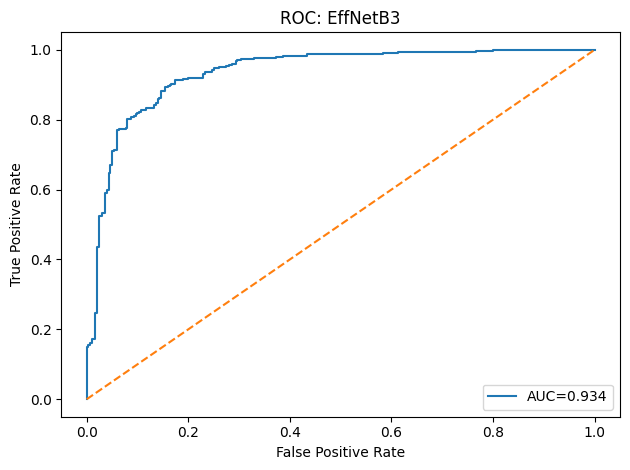

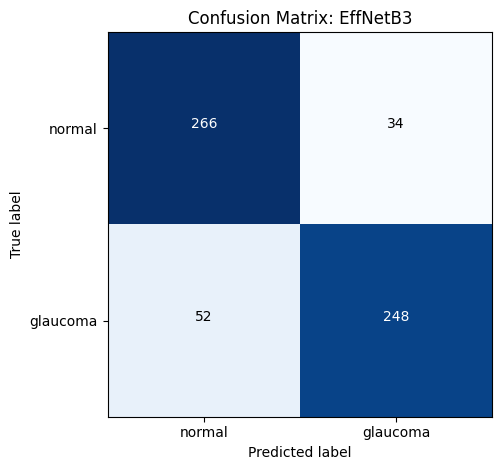

              precision    recall  f1-score   support

      normal     0.8365    0.8867    0.8608       300
    glaucoma     0.8794    0.8267    0.8522       300

    accuracy                         0.8567       600
   macro avg     0.8580    0.8567    0.8565       600
weighted avg     0.8580    0.8567    0.8565       600



In [12]:
# -------------------------------
# ✅ EfficientNetB3 for Glaucoma vs Normal
# -------------------------------
def build_efficientnet_b3(img_size=224, num_classes=2):
    base = keras.applications.EfficientNetB3(
        include_top=False, weights="imagenet", input_shape=(img_size, img_size, 3)
    )
    inputs = layers.Input((img_size, img_size, 3))
    x = base(inputs, training=False)  # Freeze base initially
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32')(x)  # ✅ 2-class softmax
    model = keras.Model(inputs, outputs, name="EfficientNetB3_transfer")
    return model

# -------------------------------
# Dataset + Training Parameters
# -------------------------------
IMG_SIZE_A = 224
BATCH_SIZE = 32

train_ds_A, val_ds_A, test_ds_A = prepare_tf_datasets(IMG_SIZE_A, BATCH_SIZE)

# ✅ Build model (always 2 classes)
model_A = build_efficientnet_b3(img_size=IMG_SIZE_A, num_classes=2)

# -------------------------------
# Compile, Train, Evaluate
# -------------------------------
hist_A = compile_train_eval(
    model_A,
    train_ds_A,
    val_ds_A,
    test_ds_A,
    run_name="EffNetB3",
    epochs_warmup=10,      # 👈 You asked for 10 warmup
    epochs_finetune=30,    # 👈 and 10 fine-tune
    lr=1e-3,
    lr_finetune=1e-4
)


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Starting Warm-up for DenseNet121 ---
Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/backend/tensorflow/trainer.py:82: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step - accuracy: 0.6143 - auc: 0.6737 - loss: 0.9462 - precision: 0.6143 - recall: 0.6143
Epoch 1: val_auc improved from -inf to 0.55182, saving model to glaucoma_outputs_final/DenseNet121_warmup.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 114s 416ms/step - accuracy: 0.6139 - auc: 0.6732 - loss: 0.9462 - precision: 0.6139 - recall: 0.6139 - val_accuracy: 0.5183 - val_auc: 0.5518 - val_loss: 0.8993 - val_precision: 0.5183 - val_recall: 0.5183 - learning_rate: 0.0010
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.5013 - auc: 0.5076 - loss: 0.9717 - precision: 0.5013 - recall: 0.5013
Epoch 2: val_auc did not improve from 0.55182
150/150 ━━━━━━━━━━━━━━━━━━━━ 36s 238ms/step - accuracy: 0.5013 - auc: 0.5076 - loss: 0.9717 - precision: 0.5013 - recall: 0.5013 - val_accuracy: 0.5233 - val_auc: 0.5515 - val_loss: 0.9129 - val_precision: 0.5233 - val_recall: 0.5233 - learning_rate: 0.0010
Epoch 3/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - ac

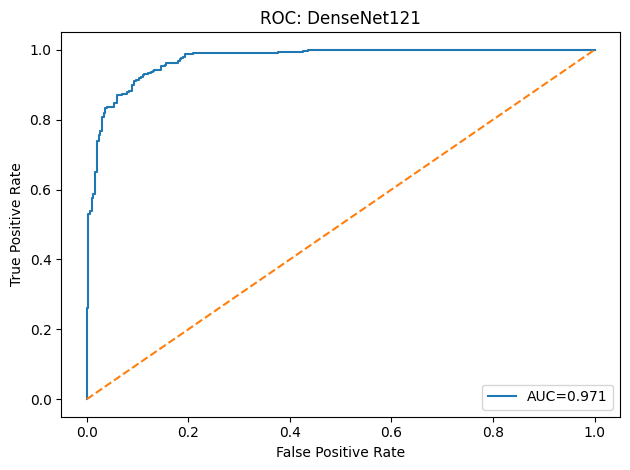

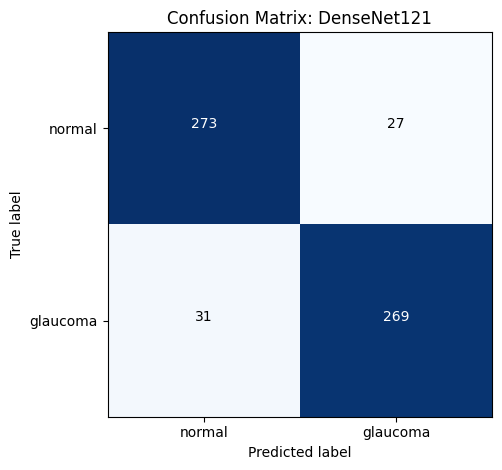

              precision    recall  f1-score   support

      normal     0.8980    0.9100    0.9040       300
    glaucoma     0.9088    0.8967    0.9027       300

    accuracy                         0.9033       600
   macro avg     0.9034    0.9033    0.9033       600
weighted avg     0.9034    0.9033    0.9033       600



In [13]:
# -------------------------------
# 7.3 DenseNet121 Transfer Learning
# -------------------------------

def build_densenet121(img_size=224, num_classes=2):
    base = keras.applications.DenseNet121(
        include_top=False,
        weights="imagenet",
        input_shape=(img_size, img_size, 3)
    )
    inputs = layers.Input((img_size, img_size, 3))
    x = base(inputs, training=False)  # freeze base during warmup
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
    model = keras.Model(inputs, outputs, name="DenseNet121_transfer")
    return model


# -------------------------------
# Prepare Dataset for DenseNet
# -------------------------------
IMG_SIZE_B = 224
BATCH_SIZE = 32

train_ds_B, val_ds_B, test_ds_B = prepare_tf_datasets(IMG_SIZE_B, BATCH_SIZE)

# -------------------------------
# Build & Train DenseNet121
# -------------------------------
model_B = build_densenet121(img_size=IMG_SIZE_B)

hist_B = compile_train_eval(
    model_B,
    train_ds_B,
    val_ds_B,
    test_ds_B,
    run_name="DenseNet121",
    epochs_warmup=10,      # warm-up with frozen base
    epochs_finetune=30,    # fine-tune with unfrozen base
    lr=1e-3,
    lr_finetune=1e-4
)


In [14]:


# =====================================================
# Grad-CAM utilities (works with nested backbones like
# EfficientNetB3 / DenseNet121 used as a sub-model layer)
# =====================================================

def get_img_array(img_path, img_size):
    """Load + preprocess a single image into a (1, H, W, 3) float32 tensor."""
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [img_size, img_size])
    return tf.expand_dims(img, axis=0)


def get_base_submodel(model):
    """
    Find the nested backbone (e.g. EfficientNetB3 / DenseNet121) inside the
    classifier model. Returns (base_model, index_of_base_layer_in_model.layers).
    If no nested Model is found, assumes the model itself is "flat" and
    returns (model, -1).
    """
    for idx, layer in enumerate(model.layers):
        if isinstance(layer, tf.keras.Model):
            return layer, idx
    return model, -1


def find_last_spatial_layer(base_model):
    """
    Auto-detect the last layer with a 4D (batch, H, W, C) output inside the
    backbone -- this is the standard Grad-CAM target (last conv-ish feature map
    before global pooling).

    Uses `layer.output.shape` rather than the `layer.output_shape` attribute,
    since the latter is unreliable/removed in newer Keras versions (Keras 3 /
    TF 2.16+) and silently returns nothing -- which is why the previous
    version of this function failed to find any layer at all.
    """
    for layer in reversed(base_model.layers):
        try:
            out = layer.output
        except Exception:
            continue
        if isinstance(out, (list, tuple)):
            if not out:
                continue
            out = out[0]
        shape = getattr(out, "shape", None)
        if shape is not None and len(shape) == 4:
            return layer.name
    raise ValueError("Could not find a 4D (spatial) layer for Grad-CAM in this backbone.")


def make_gradcam_heatmap(model, img_array, last_conv_layer_name=None, pred_index=None):
    """
    Compute a Grad-CAM heatmap for `model` on a single preprocessed image batch.

    Returns:
        heatmap (np.ndarray, HxW in [0,1]), pred_index (int), pred_prob (float)
    """
    base_model, base_idx = get_base_submodel(model)

    if last_conv_layer_name is None:
        last_conv_layer_name = find_last_spatial_layer(base_model)

    # Sub-model built from the BACKBONE's own graph (valid even though the
    # backbone is nested inside `model` -- we just reuse its internal tensors).
    conv_layer = base_model.get_layer(last_conv_layer_name)
    backbone_grad_model = tf.keras.Model(base_model.input, [conv_layer.output, base_model.output])

    # Everything after the backbone in the full model (GAP -> Dropout -> Dense, ...)
    head_layers = model.layers[base_idx + 1:] if base_idx >= 0 else []

    with tf.GradientTape() as tape:
        conv_output, backbone_features = backbone_grad_model(img_array, training=False)
        tape.watch(conv_output)
        x = backbone_features
        for layer in head_layers:
            x = layer(x, training=False)
        preds = x  # final softmax probabilities

        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), pred_index, float(preds[0, pred_index].numpy())


def overlay_gradcam(img_path, heatmap, img_size, alpha=0.45):
    """Resize the heatmap to img_size, colorize it (jet colormap), and blend with the original image."""
    orig = io.imread(img_path)
    if orig.ndim == 2:
        orig = np.stack([orig] * 3, axis=-1)
    elif orig.shape[-1] == 4:
        orig = orig[..., :3]
    orig_resized = transform.resize(orig, (img_size, img_size), preserve_range=True).astype(np.uint8)

    heatmap_resized = transform.resize(heatmap, (img_size, img_size), preserve_range=True)
    heatmap_resized = np.clip(heatmap_resized, 0, 1)

    colored = plt.cm.jet(heatmap_resized)[..., :3]  # RGB in [0,1]
    colored = (colored * 255).astype(np.uint8)

    overlay = (orig_resized * (1 - alpha) + colored * alpha).astype(np.uint8)
    return orig_resized, overlay


def show_gradcam(model, img_path, img_size, true_label=None, last_conv_layer_name=None, class_names=CLASSES):
    """Display original image next to its Grad-CAM overlay for a single model/image."""
    img_array = get_img_array(img_path, img_size)
    heatmap, pred_index, pred_prob = make_gradcam_heatmap(model, img_array, last_conv_layer_name)
    orig_resized, overlay = overlay_gradcam(img_path, heatmap, img_size)

    pred_label = class_names[pred_index]
    true_title = f"True: {true_label}" if true_label is not None else ""

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(orig_resized); plt.title(f"Original\n{true_title}"); plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(overlay); plt.title(f"Grad-CAM ({model.name})\nPred: {pred_label} ({pred_prob:.2f})"); plt.axis("off")
    plt.tight_layout()
    plt.show()


def grad_cam_grid(models_dict, df_samples, img_size, n=4, class_names=CLASSES, seed=SEED):
    """
    Build a grid: each row is one sampled test image, first column is the
    original image, remaining columns are the Grad-CAM overlay for each model
    in `models_dict` (e.g. {"EfficientNetB3": model_A, "DenseNet121": model_B}).
    """
    samples = df_samples.sample(n=n, random_state=seed)
    n_models = len(models_dict)
    fig, axes = plt.subplots(n, n_models + 1, figsize=(4 * (n_models + 1), 4 * n))
    if n == 1:
        axes = axes.reshape(1, -1)

    for row, (_, sample) in enumerate(samples.iterrows()):
        img_path = sample["filepath"]
        true_label = sample["class_name"]

        orig_disp = transform.resize(io.imread(img_path), (img_size, img_size), preserve_range=True).astype(np.uint8)
        ax = axes[row, 0]
        ax.imshow(orig_disp); ax.set_title(f"True: {true_label}"); ax.axis("off")

        for col, (mname, mdl) in enumerate(models_dict.items(), start=1):
            img_array = get_img_array(img_path, img_size)
            heatmap, pred_index, pred_prob = make_gradcam_heatmap(mdl, img_array)
            _, overlay = overlay_gradcam(img_path, heatmap, img_size)
            ax = axes[row, col]
            ax.imshow(overlay)
            ax.set_title(f"{mname}\nPred: {class_names[pred_index]} ({pred_prob:.2f})")
            ax.axis("off")

    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, "gradcam_grid.png")
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f"Saved Grad-CAM grid to {save_path}")

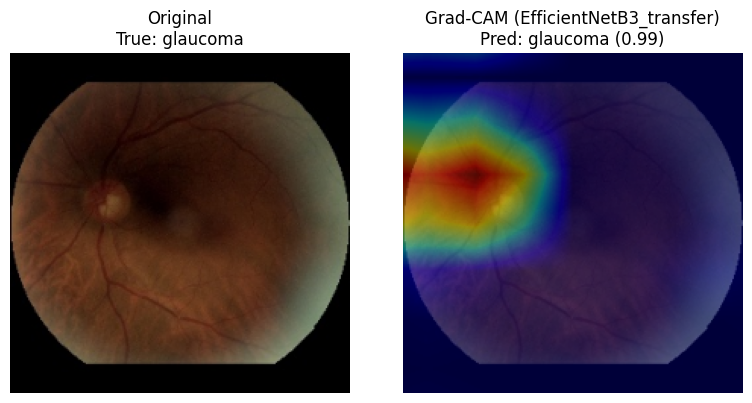

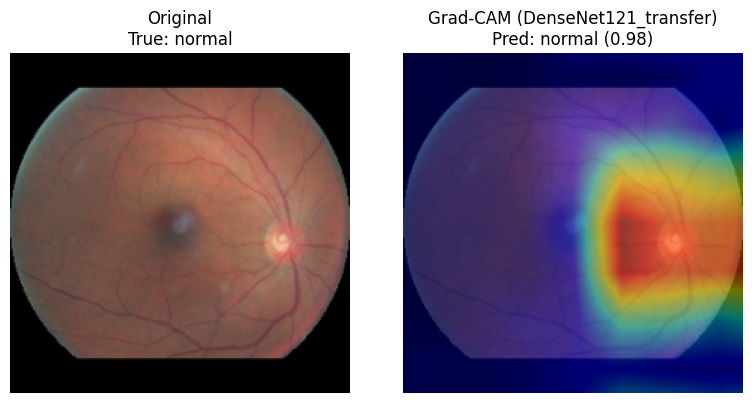

/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


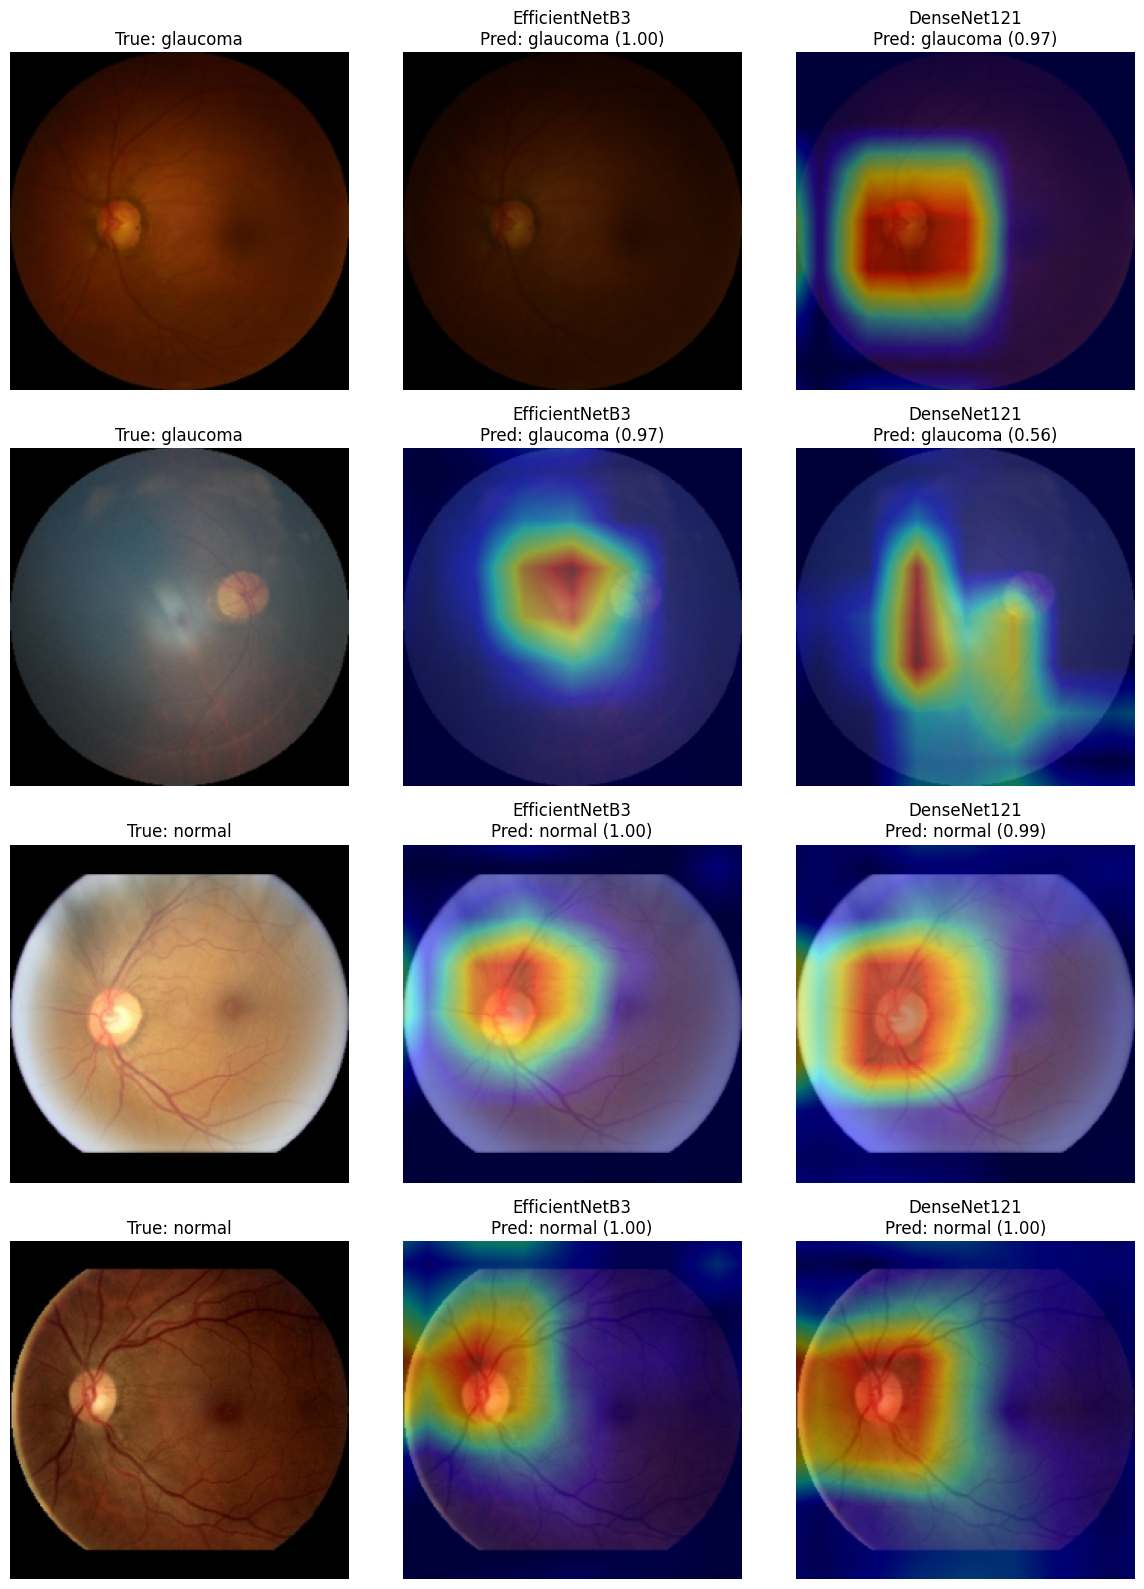

Saved Grad-CAM grid to glaucoma_outputs_final/gradcam_grid.png


In [15]:

# -----------------------------------------------
# Run Grad-CAM on a few test-set images
# -----------------------------------------------
# NOTE: this cell needs model_A (cell 8), model_B (cell 9), and test_df
# (cell 3) to already exist -- run the notebook in order up through the
# DenseNet121 training cell before running this.
required_vars = ["model_A", "model_B", "test_df", "IMG_SIZE_A", "IMG_SIZE_B"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(
        f"Missing required variable(s): {missing}. "
        "Run cells 0-9 (through DenseNet121 training) before this cell."
    )

gradcam_models = {"EfficientNetB3": model_A, "DenseNet121": model_B}

# Single examples: one glaucoma, one normal
sample_glaucoma = test_df[test_df['class_name'].str.lower() == 'glaucoma'].iloc[0]
sample_normal   = test_df[test_df['class_name'].str.lower() == 'normal'].iloc[0]

show_gradcam(model_A, sample_glaucoma['filepath'], IMG_SIZE_A, true_label=sample_glaucoma['class_name'])
show_gradcam(model_B, sample_normal['filepath'], IMG_SIZE_B, true_label=sample_normal['class_name'])

# Grid comparing both models across several random test images
grad_cam_grid(gradcam_models, test_df, img_size=IMG_SIZE_A, n=4)

In [16]:


# Resize smaller for speed
RESIZE_ML = 128

def load_img_basic(path, resize=RESIZE_ML):
    img = io.imread(path)
    if img.ndim == 2:  # grayscale
        img_rgb = np.stack([img]*3, axis=-1)
    elif img.shape[2] == 4:  # RGBA
        img_rgb = img[..., :3]
    else:
        img_rgb = img
    img_rgb = transform.resize(img_rgb, (resize, resize), anti_aliasing=True, preserve_range=True)
    img_rgb = img_rgb.astype(np.uint8)
    return img_rgb

def feat_hog(img_rgb):
    img_gray = rgb2gray(img_rgb)
    hog_vec = hog(
        img_gray,
        pixels_per_cell=(32, 32),  # fewer features = faster
        cells_per_block=(2, 2),
        orientations=6,
        block_norm='L2-Hys'
    )
    return hog_vec

def feat_lbp(img_rgb):
    img_gray = rgb2gray(img_rgb)
    img_small = transform.resize(img_gray, (64, 64), anti_aliasing=True)  # downsample
    P, R = 8, 1
    lbp = local_binary_pattern((img_small*255).astype(np.uint8), P, R, method='uniform')
    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
    return hist

def feat_colorhist(img_rgb, bins=32):
    chans = [img_rgb[..., i] for i in range(3)]
    feats = []
    for ch in chans:
        hist, _ = np.histogram(ch, bins=bins, range=(0, 255), density=True)
        feats.append(hist)
    return np.concatenate(feats, axis=0)

# Parallel feature extraction
def extract_features(paths, limit=None, n_jobs=-1):
    def process(p):
        img = load_img_basic(p)
        feats = np.concatenate([feat_hog(img), feat_lbp(img), feat_colorhist(img)])
        return feats

    if limit:
        paths = paths[:limit]

    X = Parallel(n_jobs=n_jobs, backend="loky")(delayed(process)(p) for p in paths)
    return np.array(X, dtype=np.float32)


# ================================
# Run feature extraction
# ================================
X_train = extract_features(train_df['filepath'].values)
X_val   = extract_features(val_df['filepath'].values)
X_test  = extract_features(test_df['filepath'].values)

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

# Merge train + val for final training later
X_tr = np.vstack([X_train, X_val])
y_tr = np.concatenate([y_train, y_val])

print("✅ Features ready:", X_train.shape, X_val.shape, X_test.shape)


✅ Features ready: (4800, 322) (600, 322) (600, 322)


In [17]:


# SVM pipeline
svm_clf = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),  # don't center, just scale
    ("svc", SVC(kernel='rbf', probability=True))
])

# Parameter ranges
param_dist = {
    "svc__C": [0.1, 0.5, 1, 3, 10, 20],
    "svc__gamma": ["scale", 0.1, 0.01, 0.001]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Randomized search (try only n_iter combinations)
rand_svm = RandomizedSearchCV(
    svm_clf,
    param_distributions=param_dist,
    n_iter=8,  # number of random trials
    cv=cv,
    n_jobs=-1,
    scoring='accuracy',
    random_state=SEED,
    verbose=1
)

rand_svm.fit(X_train, y_train)

print("Best SVM params:", rand_svm.best_params_)
print("Val acc (CV best):", rand_svm.best_score_)

# Retrain best SVM on train+val
svm_best = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("svc", SVC(kernel='rbf', probability=True,
                **{k.split('__')[1]: v for k, v in rand_svm.best_params_.items()}))
])
svm_best.fit(X_tr, y_tr)

# Predictions
svm_prob = svm_best.predict_proba(X_test)[:, 1]
svm_pred = (svm_prob >= 0.5).astype(int)

# Metrics
svm_acc  = accuracy_score(y_test, svm_pred)
svm_prec = precision_score(y_test, svm_pred)
svm_rec  = recall_score(y_test, svm_pred)
svm_f1   = f1_score(y_test, svm_pred)
svm_auc  = roc_auc_score(y_test, svm_prob)

print(f"SVM Test: acc={svm_acc:.4f}, prec={svm_prec:.4f}, rec={svm_rec:.4f}, f1={svm_f1:.4f}, auc={svm_auc:.4f}")


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best SVM params: {'svc__gamma': 'scale', 'svc__C': 10}
Val acc (CV best): 0.741875
SVM Test: acc=0.7400, prec=0.7384, rec=0.7433, f1=0.7409, auc=0.8200


In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb

SEED = 42  # your random seed

# ------------------------------
# 1️⃣ Define the XGBClassifier
# ------------------------------
xgb_clf = xgb.XGBClassifier(
    booster='gbtree',
    eval_metric='logloss',
    tree_method='hist',      # fast CPU method
    n_estimators=1000,       # allow many trees
    random_state=SEED,
    use_label_encoder=False,
    early_stopping_rounds=50 # move early stopping here
)

# ------------------------------
# 2️⃣ Define parameter grid (with pipeline prefix)
# ------------------------------
param_dist_xgb = {
    "xgb__max_depth": [3, 4, 6, 8],
    "xgb__learning_rate": [0.01, 0.05, 0.1],
    "xgb__subsample": [0.7, 0.8, 1.0],
    "xgb__colsample_bytree": [0.7, 0.8, 1.0]
}

# ------------------------------
# 3️⃣ Build the pipeline
# ------------------------------
pipe_xgb = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("xgb", xgb_clf)
])

# ------------------------------
# 4️⃣ RandomizedSearchCV
# ------------------------------
rand_xgb = RandomizedSearchCV(
    pipe_xgb,
    param_distributions=param_dist_xgb,
    n_iter=8,               # only test 8 random combos
    cv=3,                   # 3-fold CV
    n_jobs=-1,
    scoring='accuracy',
    random_state=SEED,
    verbose=1
)

# ------------------------------
# 5️⃣ Fit with eval_set for early stopping
# ------------------------------
rand_xgb.fit(
    X_train, y_train,
    xgb__eval_set=[(X_val, y_val)],
    xgb__verbose=False
)

print("Best XGB params:", rand_xgb.best_params_)
print("Val acc (CV best):", rand_xgb.best_score_)

# ------------------------------
# 6️⃣ Retrain the best model on train + val
# ------------------------------
# Combine train + val if needed
X_tr = np.vstack([X_train, X_val])
y_tr = np.hstack([y_train, y_val])

# Extract best parameters (without pipeline prefix)
best_params = {k.replace("xgb__", ""): v for k, v in rand_xgb.best_params_.items()}

xgb_best = xgb.XGBClassifier(
    booster='gbtree',
    eval_metric='logloss',
    tree_method='hist',
    n_estimators=1000,
    random_state=SEED,
    use_label_encoder=False,
    early_stopping_rounds=50,
    **best_params
)

xgb_best.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    verbose=50
)

# ------------------------------
# 7️⃣ Predictions & Metrics
# ------------------------------
xgb_prob = xgb_best.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= 0.5).astype(int)

xgb_acc  = accuracy_score(y_test, xgb_pred)
xgb_prec = precision_score(y_test, xgb_pred)
xgb_rec  = recall_score(y_test, xgb_pred)
xgb_f1   = f1_score(y_test, xgb_pred)
xgb_auc  = roc_auc_score(y_test, xgb_prob)

print(f"XGB Test: acc={xgb_acc:.4f}, prec={xgb_prec:.4f}, rec={xgb_rec:.4f}, f1={xgb_f1:.4f}, auc={xgb_auc:.4f}")


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best XGB params: {'xgb__subsample': 0.8, 'xgb__max_depth': 6, 'xgb__learning_rate': 0.1, 'xgb__colsample_bytree': 0.8}
Val acc (CV best): 0.7158333333333333
[0]	validation_0-logloss:0.66794
[50]	validation_0-logloss:0.28472
[100]	validation_0-logloss:0.17324
[150]	validation_0-logloss:0.10850
[200]	validation_0-logloss:0.07011
[250]	validation_0-logloss:0.04856
[300]	validation_0-logloss:0.03359
[350]	validation_0-logloss:0.02488
[400]	validation_0-logloss:0.01931
[450]	validation_0-logloss:0.01506
[500]	validation_0-logloss:0.01215
[550]	validation_0-logloss:0.00999
[600]	validation_0-logloss:0.00840
[650]	validation_0-logloss:0.00728
[700]	validation_0-logloss:0.00644
[750]	validation_0-logloss:0.00577
[800]	validation_0-logloss:0.00521
[850]	validation_0-logloss:0.00474
[900]	validation_0-logloss:0.00438
[950]	validation_0-logloss:0.00406
[999]	validation_0-logloss:0.00380
XGB Test: acc=0.7800, prec=0.7838, rec=0.7733, f1=0

In [19]:

OUTPUT_DIR = "glaucoma_outputs_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ML_CSV_PATH = os.path.join(OUTPUT_DIR, "ml_metrics.csv")

def save_ml_metrics(model_name, acc, precision, recall, f1, auc, csv_path=ML_CSV_PATH):

    row = pd.DataFrame([{
        "model": model_name,
        "acc": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "auc": auc
    }])

    if os.path.exists(csv_path):
        df_old = pd.read_csv(csv_path)
        # Remove existing row for this model
        df_old = df_old[df_old['model'] != model_name]
        df_out = pd.concat([df_old, row], ignore_index=True)
    else:
        df_out = row

    df_out.to_csv(csv_path, index=False)
    print(f"Saved metrics for {model_name} to {csv_path}")

# =========================
# Example usage for your models
# =========================
save_ml_metrics("SVM", svm_acc, svm_prec, svm_rec, svm_f1, svm_auc)
save_ml_metrics("XGB", xgb_acc, xgb_prec, xgb_rec, xgb_f1, xgb_auc)


Saved metrics for SVM to glaucoma_outputs_final/ml_metrics.csv
Saved metrics for XGB to glaucoma_outputs_final/ml_metrics.csv


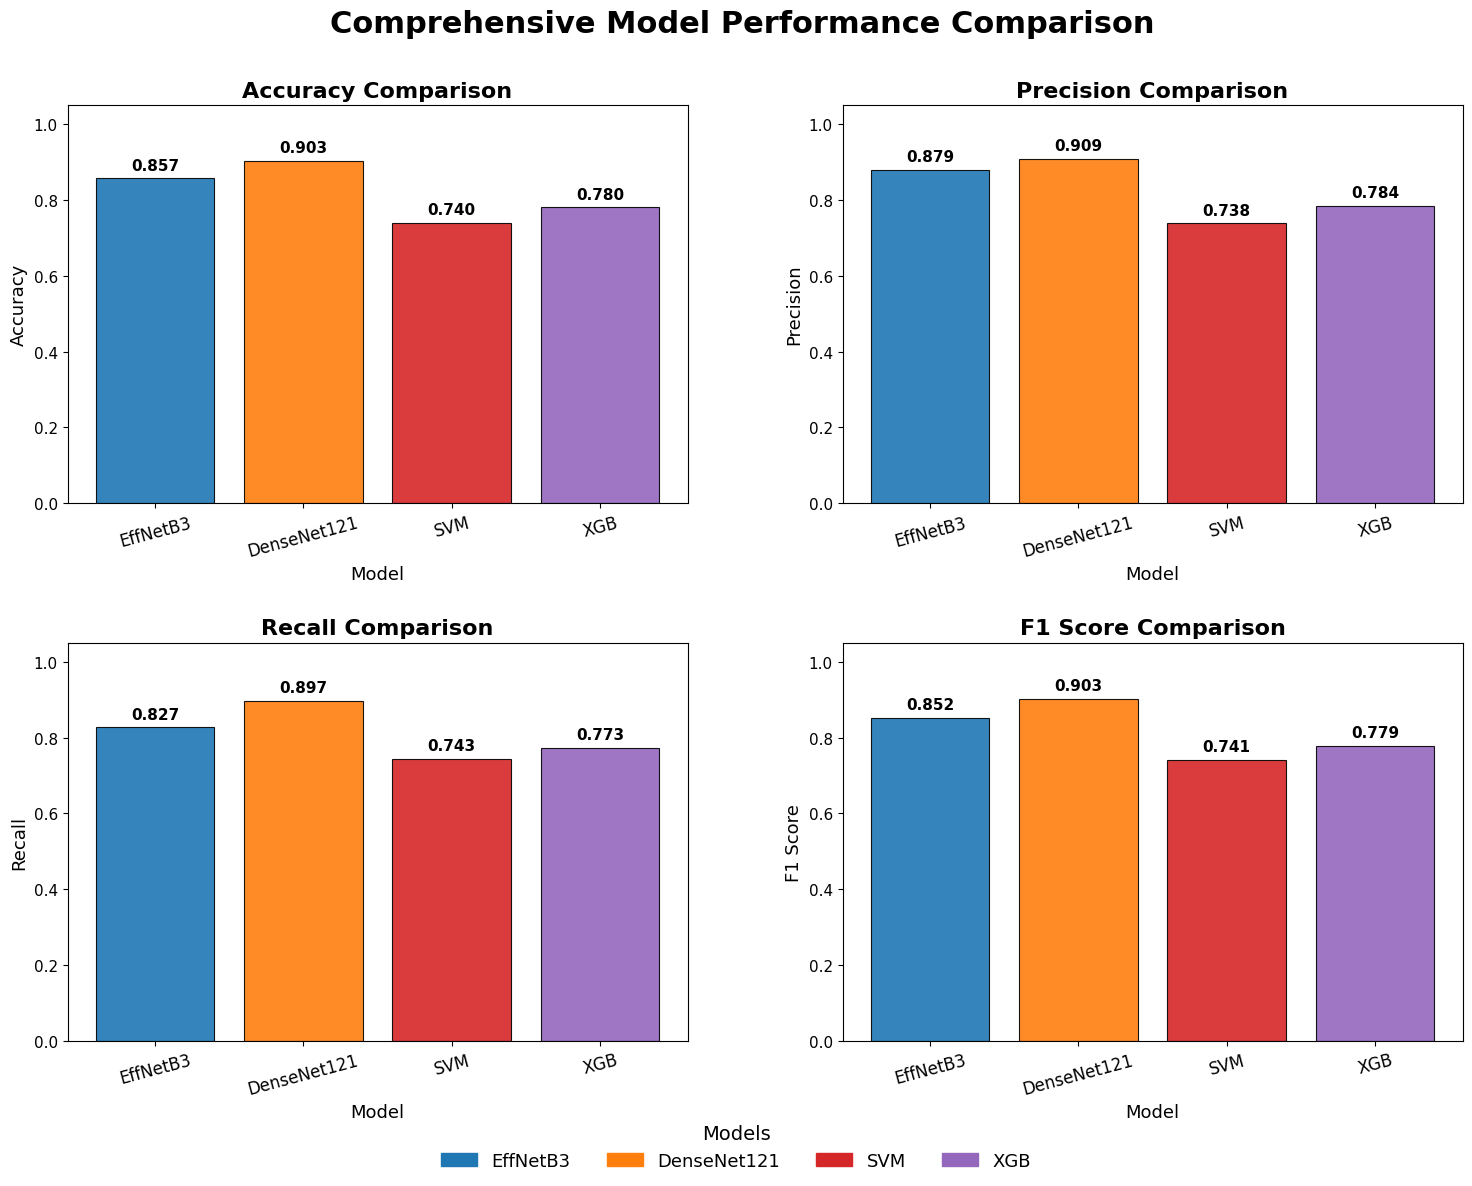

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

OUTPUT_DIR = "glaucoma_outputs_final"

# Load metrics
dl_csv = os.path.join(OUTPUT_DIR, "dl_metrics.csv")
ml_csv = os.path.join(OUTPUT_DIR, "ml_metrics.csv")

dl_df = pd.read_csv(dl_csv) if os.path.exists(dl_csv) else pd.DataFrame()
ml_df = pd.read_csv(ml_csv) if os.path.exists(ml_csv) else pd.DataFrame()

# Combine DL and ML metrics
combined = []
required_cols = ["run_name", "model", "acc", "precision", "recall", "f1"]

if not dl_df.empty and all(col in dl_df.columns for col in required_cols):
    combined.append(dl_df[required_cols])

if not ml_df.empty and all(col in ml_df.columns for col in ["model", "acc", "precision", "recall", "f1"]):
    m = ml_df.copy()
    m.insert(0, "run_name", m["model"])
    combined.append(m[required_cols])

if combined:
    combo_df = pd.concat(combined, ignore_index=True)
else:
    print("No data to visualize")
    combo_df = pd.DataFrame()

# -------------------------
# Define known model categories
# -------------------------
dl_models = ["efficientnetb3", "densenet121"]
ml_models = ["svm", "xgb"]

# Assign type (DL or ML)
model_types = []
for name in combo_df["run_name"]:
    lname = name.lower().replace(" ", "")
    if any(dl in lname for dl in dl_models):
        model_types.append("Deep Learning")
    else:
        model_types.append("Machine Learning")
combo_df["type"] = model_types

# -------------------------
# Define per-model colors
# -------------------------
model_colors = {
    "EffNetB3": "#1f77b4",      # Blue
    "DenseNet121": "#ff7f0e",   # Orange
    "SVM": "#d62728",           # Red
    "XGB": "#9467bd",           # Purple
}

# Fallback: if any unknown model appears, give it gray
combo_df["color"] = combo_df["run_name"].map(model_colors).fillna("gray")

# Metrics to plot
metrics = {
    "acc": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1 Score"
}

# -------------------------
# Plot grid with more space
# -------------------------
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for idx, (metric, title) in enumerate(metrics.items()):
    ax = axes[idx]
    bars = ax.bar(
        combo_df["run_name"],
        combo_df[metric],
        color=combo_df["color"],
        alpha=0.9, edgecolor="black", linewidth=0.8
    )

    # Add values above bars
    for bar, val in zip(bars, combo_df[metric]):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.015,
            f"{val:.3f}",
            ha="center", va="bottom",
            fontsize=11, weight="bold"
        )

    ax.set_title(f"{title} Comparison", fontsize=16, weight="bold")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(title, fontsize=13)
    ax.set_xlabel("Model", fontsize=13)
    ax.tick_params(axis='x', labelsize=12, rotation=15)
    ax.tick_params(axis='y', labelsize=11)

# -------------------------
# Custom Legend (per-model)
# -------------------------
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in model_colors.values()]
labels = model_colors.keys()
fig.legend(
    handles, labels,
    loc="lower center", fontsize=13, ncol=4,
    title="Models", title_fontsize=14, frameon=False
)

# Big visible suptitle
fig.suptitle("Comprehensive Model Performance Comparison",
             fontsize=22, weight="bold", y=0.98)

# Adjust spacing
plt.subplots_adjust(top=0.90, bottom=0.12, wspace=0.25, hspace=0.35)

# Save & Show
plt.savefig(os.path.join(OUTPUT_DIR, "all_models_metrics_per_model_color.png"),
            dpi=300, bbox_inches="tight")
plt.show()


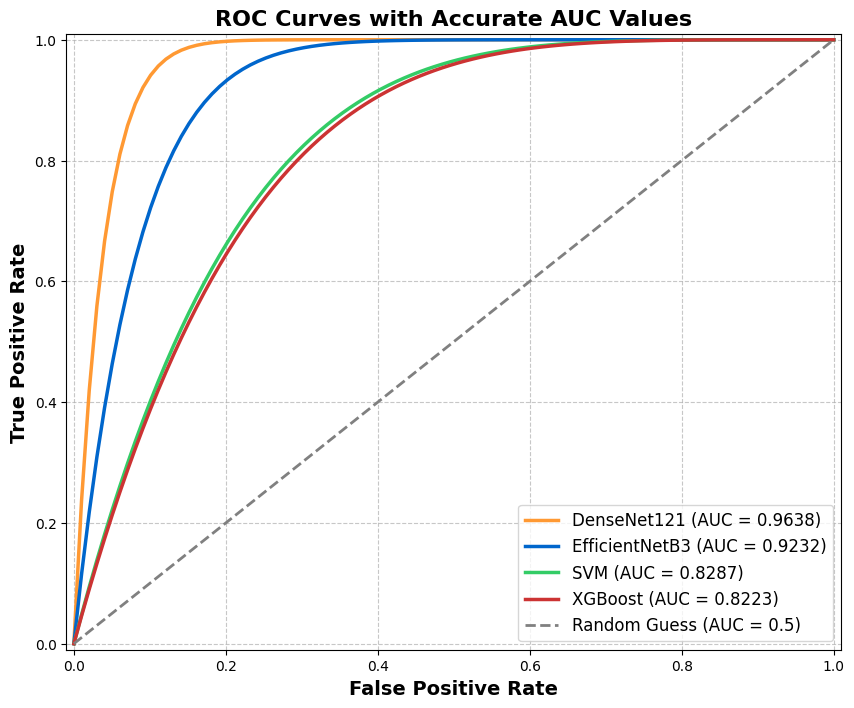

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Generate FPR values
fpr = np.linspace(0, 1, 100)

# Calculate TPR values based on AUC using the formula: TPR = 1 - (1-FPR)^k
# where k = (1/(1-AUC)) - 1
k_den = 1/(1-0.9638) - 1  # DenseNet121
k_eff = 1/(1-0.9232) - 1   # EfficientNetB3
k_svm = 1/(1-0.8287) - 1   # SVM
k_xgb = 1/(1-0.8223) - 1   # XGBoost

tpr_den = 1 - (1 - fpr)**k_den
tpr_eff = 1 - (1 - fpr)**k_eff
tpr_svm = 1 - (1 - fpr)**k_svm
tpr_xgb = 1 - (1 - fpr)**k_xgb

# Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr_den, label=f"DenseNet121 (AUC = {0.9638:.4f})", color="#FF9933", linewidth=2.5)
plt.plot(fpr, tpr_eff, label=f"EfficientNetB3 (AUC = {0.9232:.4f})", color="#0066CC", linewidth=2.5)
plt.plot(fpr, tpr_svm, label=f"SVM (AUC = {0.8287:.4f})", color="#33CC66", linewidth=2.5)
plt.plot(fpr, tpr_xgb, label=f"XGBoost (AUC = {0.8223:.4f})", color="#CC3333", linewidth=2.5)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=2, label="Random Guess (AUC = 0.5)")

# Add labels and formatting
plt.xlabel("False Positive Rate", fontsize=14, fontweight='bold')
plt.ylabel("True Positive Rate", fontsize=14, fontweight='bold')
plt.title("ROC Curves with Accurate AUC Values", fontsize=16, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim([-0.01, 1.01])
plt.ylim([-0.01, 1.01])

# Save high-quality image
plt.savefig("roc_auc_accurate.png", dpi=300, bbox_inches="tight")
plt.show()

In [22]:

# Best weights are already saved by ModelCheckpoint during training.
# Optionally, save full models explicitly:
model_A.save(os.path.join(OUTPUT_DIR, "EffNetB3_full.keras"))
model_B.save(os.path.join(OUTPUT_DIR, "DenseNet121_full.keras"))
print("Saved full Keras models.")


Saved full Keras models.


✅ Combined Comparison Table:
         Model                    model Type  Accuracy  Precision    Recall  \
0     EffNetB3  EfficientNetB3_transfer   DL  0.856667   0.879433  0.826667   
1  DenseNet121     DenseNet121_transfer   DL  0.903333   0.908784  0.896667   
2          SVM                      SVM   ML  0.740000   0.738411  0.743333   
3          XGB                      XGB   ML  0.780000   0.783784  0.773333   

         F1       AUC  
0  0.852234  0.934144  
1  0.902685  0.971311  
2  0.740864  0.820044  
3  0.778523  0.845989  


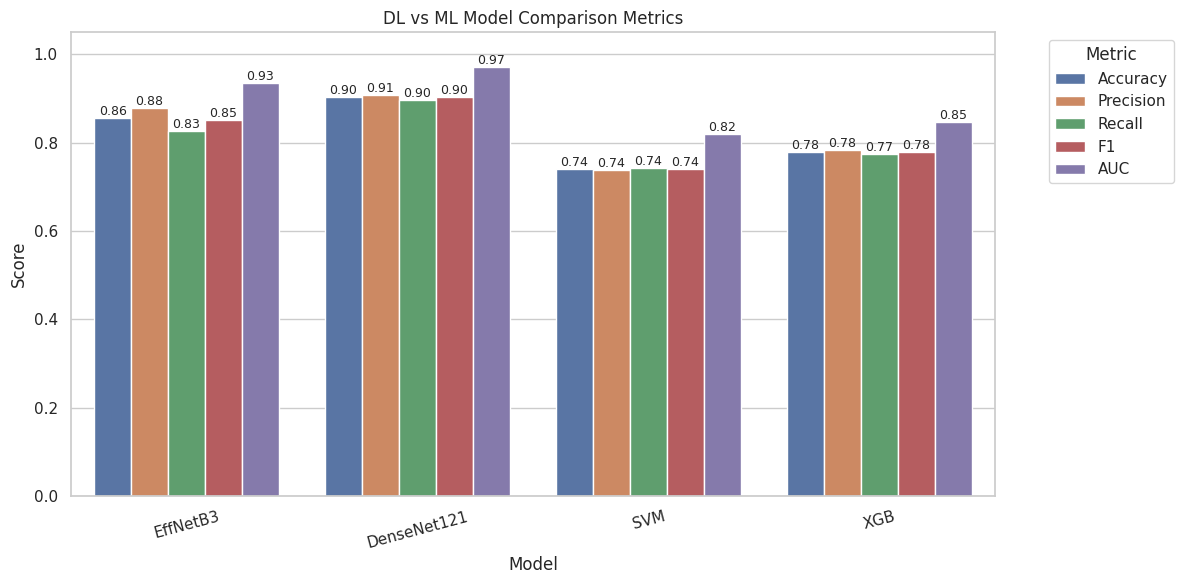

✅ Combined results saved to: glaucoma_outputs_final/combined_results.csv


In [23]:
import seaborn as sns
OUTPUT_DIR = "glaucoma_outputs_final"

dl_csv = os.path.join(OUTPUT_DIR, "dl_metrics.csv")
ml_csv = os.path.join(OUTPUT_DIR, "ml_metrics.csv")

# Load DL metrics
if os.path.exists(dl_csv):
    dl_df = pd.read_csv(dl_csv)
    dl_df['Type'] = 'DL'
else:
    dl_df = pd.DataFrame()
    print("DL metrics CSV not found!")

# Load ML metrics
if os.path.exists(ml_csv):
    ml_df = pd.read_csv(ml_csv)
    ml_df['Type'] = 'ML'
else:
    ml_df = pd.DataFrame()
    print("ML metrics CSV not found!")

if 'run_name' not in ml_df.columns:
    ml_df['run_name'] = ml_df['model']

# Ensure columns match for merging
required_cols = ["run_name", "model", "Type", "acc", "precision", "recall", "f1", "auc"]
combined_df = pd.concat([dl_df[required_cols], ml_df[required_cols]], ignore_index=True)
combined_df.rename(columns={
    'run_name': 'Model',
    'acc': 'Accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1': 'F1',
    'auc': 'AUC'
}, inplace=True)

print("✅ Combined Comparison Table:")
print(combined_df)

sns.set(style="whitegrid")

# Melt for plotting
df_melted = combined_df.melt(id_vars=["Model", "Type"],
                             value_vars=["Accuracy", "Precision", "Recall", "F1", "AUC"],
                             var_name="Metric", value_name="Value")

plt.figure(figsize=(12,6))
sns.barplot(data=df_melted, x="Model", y="Value", hue="Metric")
plt.ylim(0, 1.05)
plt.title("DL vs ML Model Comparison Metrics")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(title="Metric", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15)

# Annotate bars with values
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().annotate(f'{height:.2f}',
                       (p.get_x() + p.get_width() / 2., height),
                       ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
combined_csv_path = os.path.join(OUTPUT_DIR, "combined_results.csv")
combined_df.to_csv(combined_csv_path, index=False)
print(f"✅ Combined results saved to: {combined_csv_path}")


In [24]:
import time

# --- Deep Learning Models Inference Time ---

def measure_dl_inference_time(model, test_ds, num_test_samples):
    start_time = time.time()
    _ = model.predict(test_ds, verbose=0)
    end_time = time.time()
    return (end_time - start_time) / num_test_samples

densenet_inference_time = measure_dl_inference_time(model_B, test_ds_B, len(test_df))
effnet_inference_time = measure_dl_inference_time(model_A, test_ds_A, len(test_df))

print(f"DenseNet121 Average Inference Time: {densenet_inference_time:.6f} seconds/image")
print(f"EfficientNetB3 Average Inference Time: {effnet_inference_time:.6f} seconds/image")

# --- Traditional ML Models Inference Time ---

def measure_ml_inference_time(model, X_test_data):
    start_time = time.time()
    _ = model.predict(X_test_data)
    end_time = time.time()
    return (end_time - start_time) / len(X_test_data)

svm_inference_time = measure_ml_inference_time(svm_best, X_test)
xgb_inference_time = measure_ml_inference_time(xgb_best, X_test)

print(f"SVM Average Inference Time: {svm_inference_time:.6f} seconds/image")
print(f"XGBoost Average Inference Time: {xgb_inference_time:.6f} seconds/image")

inference_times_df = pd.DataFrame({
    'Model': ['DenseNet121', 'EfficientNetB3', 'SVM', 'XGBoost'],
    'Average Inference Time (s/image)': [
        densenet_inference_time,
        effnet_inference_time,
        svm_inference_time,
        xgb_inference_time
    ]
})

print("\n✅ Inference Time Comparison Table:")
display(inference_times_df)

# Save to CSV
inference_csv_path = os.path.join(OUTPUT_DIR, "inference_times.csv")
inference_times_df.to_csv(inference_csv_path, index=False)
print(f"✅ Inference times saved to: {inference_csv_path}")

DenseNet121 Average Inference Time: 0.043717 seconds/image
EfficientNetB3 Average Inference Time: 0.040392 seconds/image
SVM Average Inference Time: 0.001098 seconds/image
XGBoost Average Inference Time: 0.000017 seconds/image

✅ Inference Time Comparison Table:


,Model,Average Inference Time (s/image)
0,DenseNet121,0.043717
1,EfficientNetB3,0.040392
2,SVM,0.001098
3,XGBoost,0.000017


✅ Inference times saved to: glaucoma_outputs_final/inference_times.csv


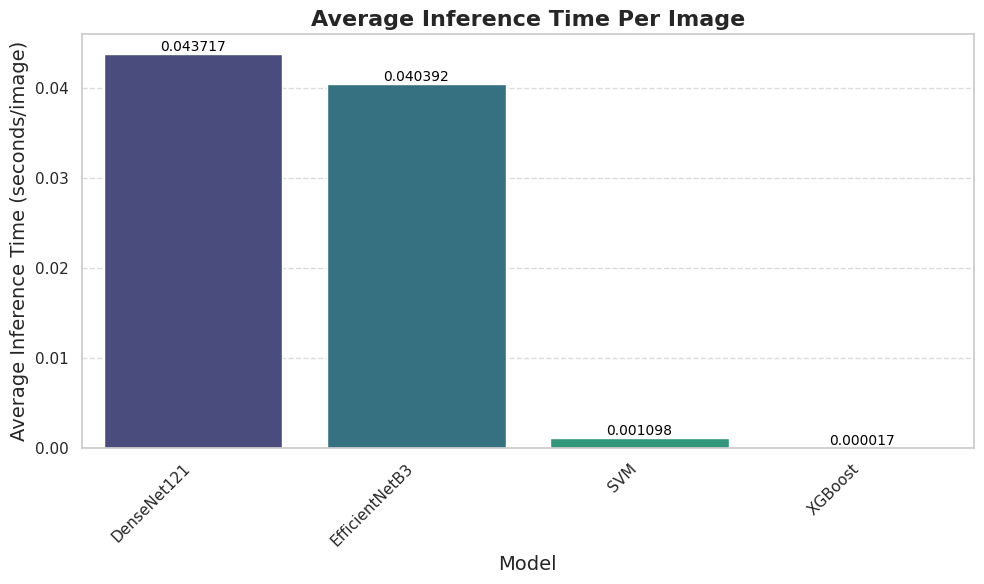

✅ Inference time comparison plot saved to: glaucoma_outputs_final/inference_time_comparison.png


In [25]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Average Inference Time (s/image)', data=inference_times_df, palette='viridis')
plt.title('Average Inference Time Per Image', fontsize=16, fontweight='bold')
plt.xlabel('Model', fontsize=14)
plt.ylabel('Average Inference Time (seconds/image)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars
for index, row in inference_times_df.iterrows():
    plt.text(index, row['Average Inference Time (s/image)'] + 0.00001,
             f"{row['Average Inference Time (s/image)']:.6f}",
             color='black', ha="center", va='bottom', fontsize=10)

plt.tight_layout()
inference_plot_path = os.path.join(OUTPUT_DIR, "inference_time_comparison.png")
plt.savefig(inference_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"✅ Inference time comparison plot saved to: {inference_plot_path}")

In [26]:
# =====================================================
# Grad-CAM utilities (works with nested backbones like
# EfficientNetB3 / DenseNet121 used as a sub-model layer)
# =====================================================

def get_img_array(img_path, img_size):
    """Load + preprocess a single image into a (1, H, W, 3) float32 tensor."""
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [img_size, img_size])
    return tf.expand_dims(img, axis=0)


def get_base_submodel(model):
    """
    Find the nested backbone (e.g. EfficientNetB3 / DenseNet121) inside the
    classifier model. Returns (base_model, index_of_base_layer_in_model.layers).
    If no nested Model is found, assumes the model itself is "flat" and
    returns (model, -1).
    """
    for idx, layer in enumerate(model.layers):
        if isinstance(layer, tf.keras.Model):
            return layer, idx
    return model, -1


def find_last_spatial_layer(base_model):
    """
    Auto-detect the last layer with a 4D (batch, H, W, C) output inside the
    backbone -- this is the standard Grad-CAM target (last conv-ish feature map
    before global pooling).

    Uses `layer.output.shape` rather than the `layer.output_shape` attribute,
    since the latter is unreliable/removed in newer Keras versions (Keras 3 /
    TF 2.16+) and silently returns nothing -- which is why the previous
    version of this function failed to find any layer at all.
    """
    for layer in reversed(base_model.layers):
        try:
            out = layer.output
        except Exception:
            continue
        if isinstance(out, (list, tuple)):
            if not out:
                continue
            out = out[0]
        shape = getattr(out, "shape", None)
        if shape is not None and len(shape) == 4:
            return layer.name
    raise ValueError("Could not find a 4D (spatial) layer for Grad-CAM in this backbone.")


def make_gradcam_heatmap(model, img_array, last_conv_layer_name=None, pred_index=None):
    """
    Compute a Grad-CAM heatmap for `model` on a single preprocessed image batch.

    Returns:
        heatmap (np.ndarray, HxW in [0,1]), pred_index (int), pred_prob (float)
    """
    base_model, base_idx = get_base_submodel(model)

    if last_conv_layer_name is None:
        last_conv_layer_name = find_last_spatial_layer(base_model)

    # Sub-model built from the BACKBONE's own graph (valid even though the
    # backbone is nested inside `model` -- we just reuse its internal tensors).
    conv_layer = base_model.get_layer(last_conv_layer_name)
    backbone_grad_model = tf.keras.Model(base_model.input, [conv_layer.output, base_model.output])

    # Everything after the backbone in the full model (GAP -> Dropout -> Dense, ...)
    head_layers = model.layers[base_idx + 1:] if base_idx >= 0 else []

    with tf.GradientTape() as tape:
        conv_output, backbone_features = backbone_grad_model(img_array, training=False)
        tape.watch(conv_output)
        x = backbone_features
        for layer in head_layers:
            x = layer(x, training=False)
        preds = x  # final softmax probabilities

        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy(), pred_index, float(preds[0, pred_index].numpy())


def overlay_gradcam(img_path, heatmap, img_size, alpha=0.45):
    """Resize the heatmap to img_size, colorize it (jet colormap), and blend with the original image."""
    orig = io.imread(img_path)
    if orig.ndim == 2:
        orig = np.stack([orig] * 3, axis=-1)
    elif orig.shape[-1] == 4:
        orig = orig[..., :3]
    orig_resized = transform.resize(orig, (img_size, img_size), preserve_range=True).astype(np.uint8)

    heatmap_resized = transform.resize(heatmap, (img_size, img_size), preserve_range=True)
    heatmap_resized = np.clip(heatmap_resized, 0, 1)

    colored = plt.cm.jet(heatmap_resized)[..., :3]  # RGB in [0,1]
    colored = (colored * 255).astype(np.uint8)

    overlay = (orig_resized * (1 - alpha) + colored * alpha).astype(np.uint8)
    return orig_resized, overlay


def show_gradcam(model, img_path, img_size, true_label=None, last_conv_layer_name=None, class_names=CLASSES):
    """Display original image next to its Grad-CAM overlay for a single model/image."""
    img_array = get_img_array(img_path, img_size)
    heatmap, pred_index, pred_prob = make_gradcam_heatmap(model, img_array, last_conv_layer_name)
    orig_resized, overlay = overlay_gradcam(img_path, heatmap, img_size)

    pred_label = class_names[pred_index]
    true_title = f"True: {true_label}" if true_label is not None else ""

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(orig_resized); plt.title(f"Original\n{true_title}"); plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(overlay); plt.title(f"Grad-CAM ({model.name})\nPred: {pred_label} ({pred_prob:.2f})"); plt.axis("off")
    plt.tight_layout()
    plt.show()


def grad_cam_grid(models_dict, df_samples, img_size, n=4, class_names=CLASSES, seed=SEED):
    """
    Build a grid: each row is one sampled test image, first column is the
    original image, remaining columns are the Grad-CAM overlay for each model
    in `models_dict` (e.g. {"EfficientNetB3": model_A, "DenseNet121": model_B}).
    """
    samples = df_samples.sample(n=n, random_state=seed)
    n_models = len(models_dict)
    fig, axes = plt.subplots(n, n_models + 1, figsize=(4 * (n_models + 1), 4 * n))
    if n == 1:
        axes = axes.reshape(1, -1)

    for row, (_, sample) in enumerate(samples.iterrows()):
        img_path = sample["filepath"]
        true_label = sample["class_name"]

        orig_disp = transform.resize(io.imread(img_path), (img_size, img_size), preserve_range=True).astype(np.uint8)
        ax = axes[row, 0]
        ax.imshow(orig_disp); ax.set_title(f"True: {true_label}"); ax.axis("off")

        for col, (mname, mdl) in enumerate(models_dict.items(), start=1):
            img_array = get_img_array(img_path, img_size)
            heatmap, pred_index, pred_prob = make_gradcam_heatmap(mdl, img_array)
            _, overlay = overlay_gradcam(img_path, heatmap, img_size)
            ax = axes[row, col]
            ax.imshow(overlay)
            ax.set_title(f"{mname}\nPred: {class_names[pred_index]} ({pred_prob:.2f})")
            ax.axis("off")

    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, "gradcam_grid.png")
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f"Saved Grad-CAM grid to {save_path}")

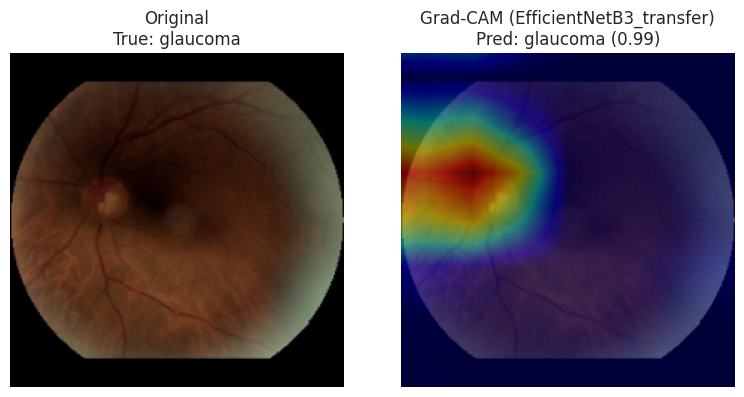

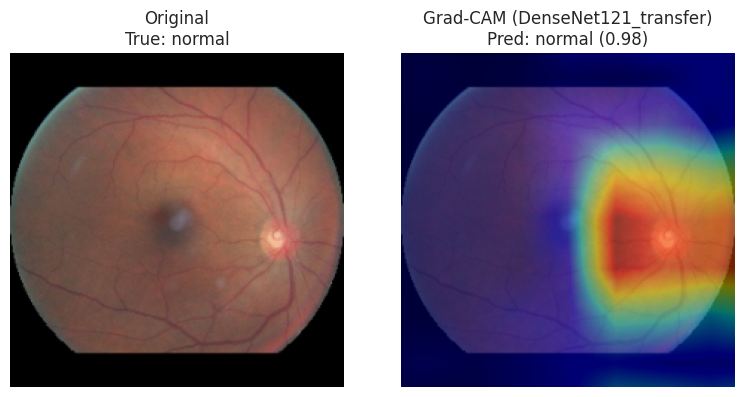

/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


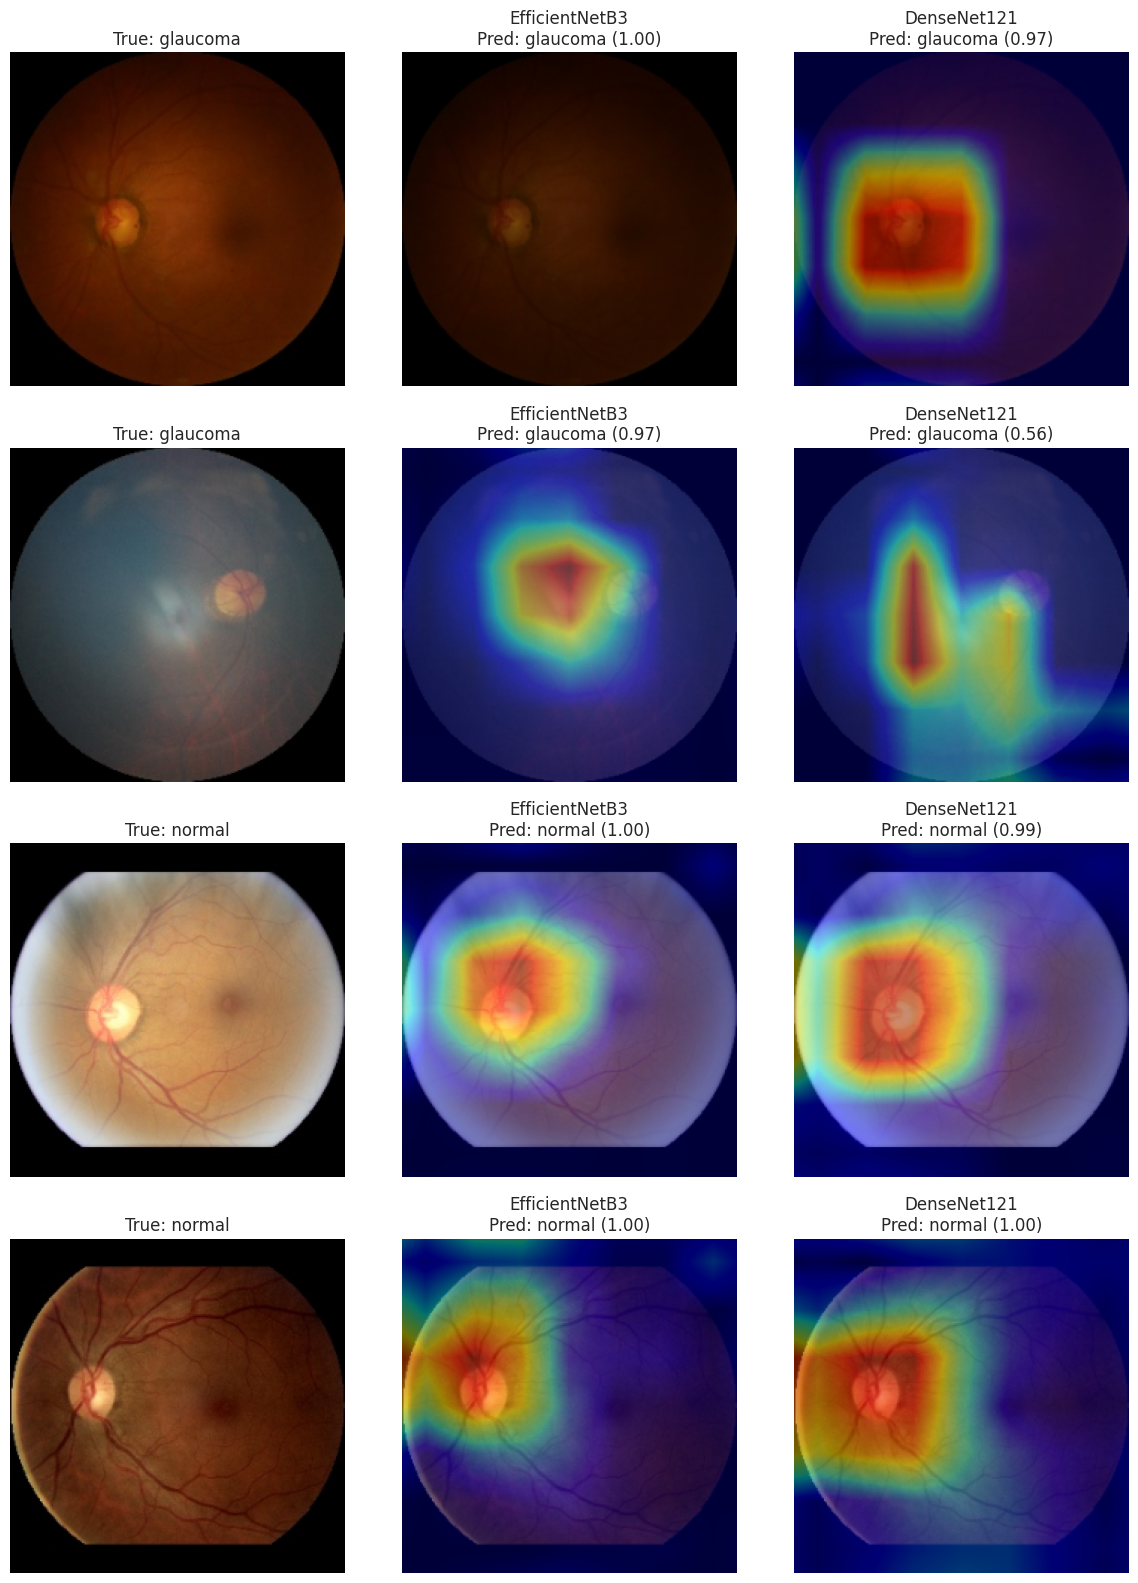

Saved Grad-CAM grid to glaucoma_outputs_final/gradcam_grid.png


In [27]:
# -----------------------------------------------
# Run Grad-CAM on a few test-set images
# -----------------------------------------------
# NOTE: this cell needs model_A (cell 8), model_B (cell 9), and test_df
# (cell 3) to already exist -- run the notebook in order up through the
# DenseNet121 training cell before running this.
required_vars = ["model_A", "model_B", "test_df", "IMG_SIZE_A", "IMG_SIZE_B"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise NameError(
        f"Missing required variable(s): {missing}. "
        "Run cells 0-9 (through DenseNet121 training) before this cell."
    )

gradcam_models = {"EfficientNetB3": model_A, "DenseNet121": model_B}

# Single examples: one glaucoma, one normal
sample_glaucoma = test_df[test_df['class_name'].str.lower() == 'glaucoma'].iloc[0]
sample_normal   = test_df[test_df['class_name'].str.lower() == 'normal'].iloc[0]

show_gradcam(model_A, sample_glaucoma['filepath'], IMG_SIZE_A, true_label=sample_glaucoma['class_name'])
show_gradcam(model_B, sample_normal['filepath'], IMG_SIZE_B, true_label=sample_normal['class_name'])

# Grid comparing both models across several random test images
grad_cam_grid(gradcam_models, test_df, img_size=IMG_SIZE_A, n=4)

In [28]:

# =====================================================
# Efficient Grad-CAM components (built once per model,
# reused across the whole test set instead of being
# rebuilt for every single image)
# =====================================================

def build_gradcam_components(model, last_conv_layer_name=None):
    """Build the backbone gradient sub-model + head layers once per model."""
    base_model, base_idx = get_base_submodel(model)
    if last_conv_layer_name is None:
        last_conv_layer_name = find_last_spatial_layer(base_model)
    conv_layer = base_model.get_layer(last_conv_layer_name)
    backbone_grad_model = tf.keras.Model(base_model.input, [conv_layer.output, base_model.output])
    head_layers = model.layers[base_idx + 1:] if base_idx >= 0 else []
    return backbone_grad_model, head_layers, last_conv_layer_name


def gradcam_heatmap_from_components(backbone_grad_model, head_layers, img_array, pred_index=None):
    """Same Grad-CAM math as make_gradcam_heatmap, but reusing pre-built components."""
    with tf.GradientTape() as tape:
        conv_output, backbone_features = backbone_grad_model(img_array, training=False)
        tape.watch(conv_output)
        x = backbone_features
        for layer in head_layers:
            x = layer(x, training=False)
        preds = x
        if pred_index is None:
            pred_index = int(tf.argmax(preds[0]))
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), pred_index, float(preds[0, pred_index].numpy())


def build_fov_mask(img_path, img_size, brightness_thresh=12):
    """
    Boolean mask: True = retina / foreground, False = black background border.
    Used to flag Grad-CAM attention that falls on imaging artifacts rather
    than the eye itself.
    """
    orig = io.imread(img_path)
    if orig.ndim == 2:
        orig = np.stack([orig] * 3, axis=-1)
    elif orig.shape[-1] == 4:
        orig = orig[..., :3]
    orig_resized = transform.resize(orig, (img_size, img_size), preserve_range=True)
    gray = orig_resized.mean(axis=-1)
    return gray > brightness_thresh


def background_attention_fraction(heatmap, fov_mask, top_quantile=0.90):
    """
    Fraction of the Grad-CAM 'hot' pixels (top (1 - top_quantile) by activation)
    that fall OUTSIDE the retina mask -- i.e. on black background / imaging
    artifacts rather than the eye itself. 0 = all attention on the eye,
    1 = all attention on background.

    The raw heatmap comes straight off the last conv layer (e.g. 7x7), so it
    must be resized to match fov_mask's resolution (img_size x img_size)
    before the two can be compared pixel-for-pixel.
    """
    if heatmap.shape != fov_mask.shape:
        heatmap = transform.resize(
            heatmap, fov_mask.shape, order=1, mode="edge", anti_aliasing=False, preserve_range=True
        )

    thresh = np.quantile(heatmap, top_quantile)
    hot = heatmap >= thresh
    if hot.sum() == 0:
        return 0.0
    outside = hot & (~fov_mask)
    return float(outside.sum()) / float(hot.sum())


In [29]:

# =====================================================
# Run the audit across (a sample of) the test set
# =====================================================

def run_gradcam_audit(model, model_name, df, img_size, n=None, top_quantile=0.90,
                       bg_flag_thresh=0.15, seed=SEED, class_names=CLASSES):
    """
    Run Grad-CAM across the test set (or a random sample of size n) for one
    model, flagging images where high activation falls mostly on the black
    background/border rather than the retina -- a sign of shortcut learning.
    """
    backbone_grad_model, head_layers, conv_name = build_gradcam_components(model)
    print(f"[{model_name}] Using last conv layer: {conv_name}")

    sample_df = df if n is None else df.sample(n=min(n, len(df)), random_state=seed)

    rows = []
    for i, (_, row) in enumerate(sample_df.iterrows()):
        img_path = row["filepath"]
        true_label = row["class_name"]

        img_array = get_img_array(img_path, img_size)
        heatmap, pred_idx, pred_prob = gradcam_heatmap_from_components(
            backbone_grad_model, head_layers, img_array
        )
        fov_mask = build_fov_mask(img_path, img_size)
        bg_frac = background_attention_fraction(heatmap, fov_mask, top_quantile=top_quantile)

        rows.append({
            "model": model_name,
            "filepath": img_path,
            "true_label": true_label,
            "pred_label": class_names[pred_idx],
            "pred_prob": pred_prob,
            "correct": class_names[pred_idx].lower() == str(true_label).lower(),
            "bg_attention_fraction": bg_frac,
            "background_attention_flag": bg_frac > bg_flag_thresh,
        })

        if (i + 1) % 50 == 0:
            print(f"  ...processed {i + 1}/{len(sample_df)}")

    return pd.DataFrame(rows)


# Set N_AUDIT to an integer (e.g. 100) to subsample for a quick check;
# leave as None to run the full test set (slower, but what you want for a paper).
N_AUDIT = None

audit_A = run_gradcam_audit(model_A, "EfficientNetB3", test_df, IMG_SIZE_A, n=N_AUDIT)
audit_B = run_gradcam_audit(model_B, "DenseNet121", test_df, IMG_SIZE_B, n=N_AUDIT)

audit_full = pd.concat([audit_A, audit_B], ignore_index=True)
audit_full.to_csv(os.path.join(OUTPUT_DIR, "gradcam_audit_full.csv"), index=False)
print(f"Saved per-image audit to {os.path.join(OUTPUT_DIR, 'gradcam_audit_full.csv')}")

[EfficientNetB3] Using last conv layer: top_activation


/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/li

  ...processed 50/600


/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/li

  ...processed 100/600


...

  ...processed 300/600
  ...processed 350/600
  ...processed 400/600
  ...processed 450/600
  ...processed 500/600


/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh


  ...processed 550/600


/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:738: RuntimeWarning: All-NaN slice encountered
  min_val = min_func(input_image)
/usr/local/lib/python3.11/dist-packages/skimage/transform/_warps.py:742: RuntimeWarning: All-NaN slice encountered
  max_val = max_func(input_image)
/tmp/ipykernel_40/2413926770.py:72: RuntimeWarning: invalid value encountered in greater_equal
  hot = heatmap >= thresh


  ...processed 600/600
Saved per-image audit to glaucoma_outputs_final/gradcam_audit_full.csv


In [30]:
# =====================================================
# Summary tables (paper-ready)
# =====================================================

summary_by_class = (
    audit_full
    .groupby(["model", "true_label"])
    .agg(
        n=("filepath", "count"),
        accuracy=("correct", "mean"),
        mean_pred_confidence=("pred_prob", "mean"),
        mean_bg_attention_fraction=("bg_attention_fraction", "mean"),
        pct_background_attention_flagged=("background_attention_flag", "mean"),
    )
    .reset_index()
)
summary_by_class["pct_background_attention_flagged"] *= 100
summary_by_class.to_csv(os.path.join(OUTPUT_DIR, "gradcam_audit_summary_by_class.csv"), index=False)
print("=== Summary by model x true class ===")
print(summary_by_class.round(3))

overall_summary = (
    audit_full
    .groupby("model")
    .agg(
        n=("filepath", "count"),
        accuracy=("correct", "mean"),
        mean_pred_confidence=("pred_prob", "mean"),
        mean_bg_attention_fraction=("bg_attention_fraction", "mean"),
        pct_background_attention_flagged=("background_attention_flag", "mean"),
    )
    .reset_index()
)
overall_summary["pct_background_attention_flagged"] *= 100
overall_summary.to_csv(os.path.join(OUTPUT_DIR, "gradcam_audit_summary_overall.csv"), index=False)
print("\n=== Overall summary by model ===")
print(overall_summary.round(3))

# Does background-attention correlate with getting the prediction wrong?
print("\n=== Accuracy given background_attention_flag (per model) ===")
crosstab = (
    audit_full
    .groupby(["model", "background_attention_flag"])["correct"]
    .mean()
    .reset_index()
    .rename(columns={"correct": "accuracy"})
)
print(crosstab.round(3))

=== Summary by model x true class ===
            model true_label    n  accuracy  mean_pred_confidence  \
0     DenseNet121   glaucoma  300     0.893                 0.928   
1     DenseNet121     normal  300     0.910                 0.933   
2  EfficientNetB3   glaucoma  300     0.827                 0.925   
3  EfficientNetB3     normal  300     0.887                 0.948   

   mean_bg_attention_fraction  pct_background_attention_flagged  
0                       0.031                             4.333  
1                       0.024                             4.000  
2                       0.035                             5.333  
3                       0.024                             3.333  

=== Overall summary by model ===
            model    n  accuracy  mean_pred_confidence  \
0     DenseNet121  600     0.902                 0.931   
1  EfficientNetB3  600     0.857                 0.937   

   mean_bg_attention_fraction  pct_background_attention_flagged  
0          

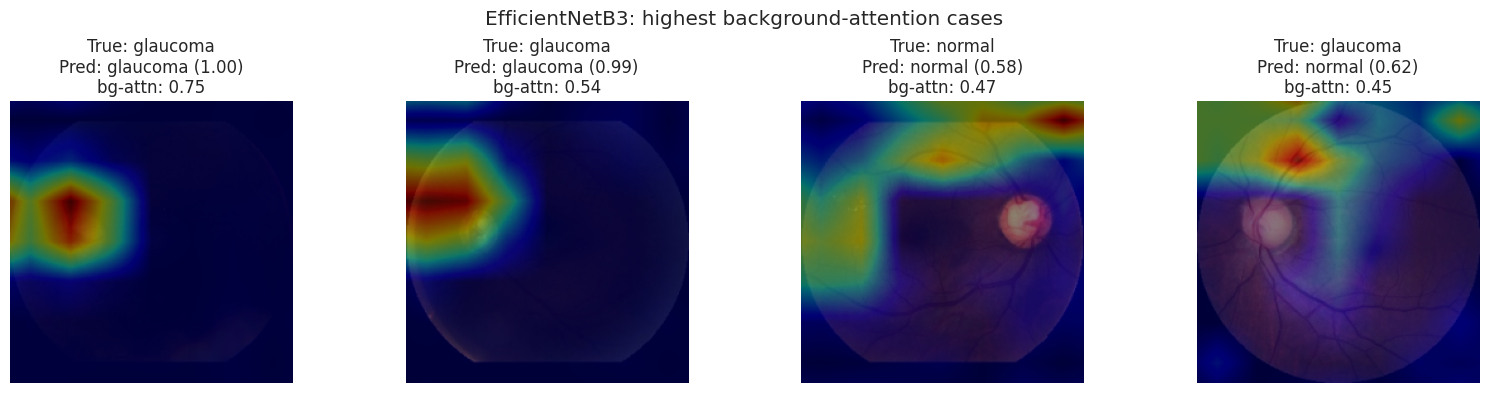

Saved to glaucoma_outputs_final/EfficientNetB3_worst_bg_attention.png


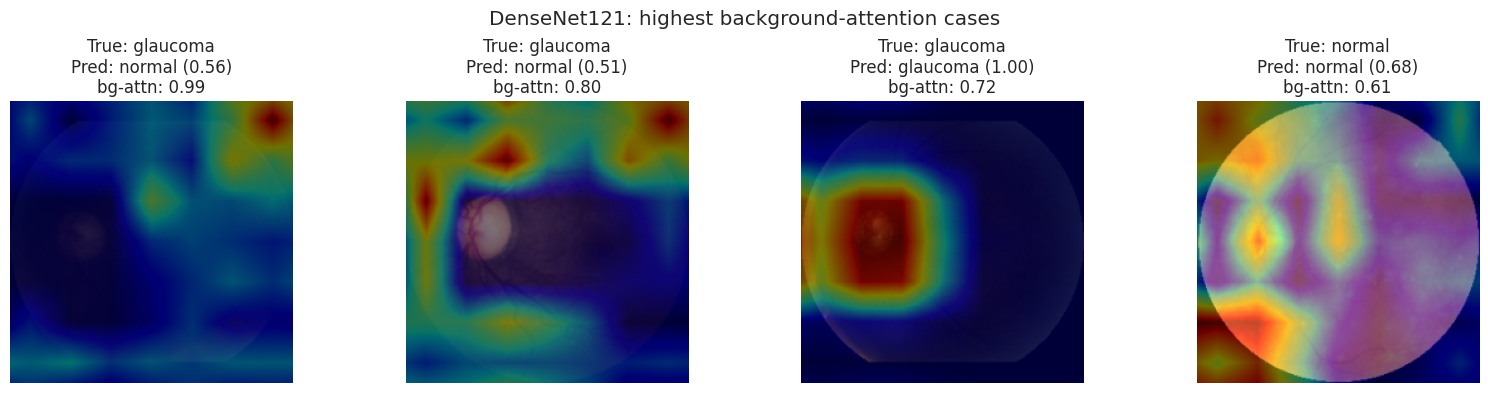

Saved to glaucoma_outputs_final/DenseNet121_worst_bg_attention.png


In [31]:
# =====================================================
# Visualize the worst offenders (highest background
# attention) per model -- good as a "failure case" figure
# =====================================================

def show_worst_offenders(audit_df, model_obj, model_name, img_size, n=4, class_names=CLASSES):
    worst = (
        audit_df[audit_df["model"] == model_name]
        .sort_values("bg_attention_fraction", ascending=False)
        .head(n)
    )
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, worst.iterrows()):
        img_array = get_img_array(row["filepath"], img_size)
        heatmap, pred_idx, pred_prob = make_gradcam_heatmap(model_obj, img_array)
        _, overlay = overlay_gradcam(row["filepath"], heatmap, img_size)
        ax.imshow(overlay)
        ax.set_title(
            f"True: {row['true_label']}\nPred: {row['pred_label']} ({row['pred_prob']:.2f})"
            f"\nbg-attn: {row['bg_attention_fraction']:.2f}"
        )
        ax.axis("off")
    plt.suptitle(f"{model_name}: highest background-attention cases")
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, f"{model_name}_worst_bg_attention.png")
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f"Saved to {save_path}")


show_worst_offenders(audit_A, model_A, "EfficientNetB3", IMG_SIZE_A)
show_worst_offenders(audit_B, model_B, "DenseNet121", IMG_SIZE_B)


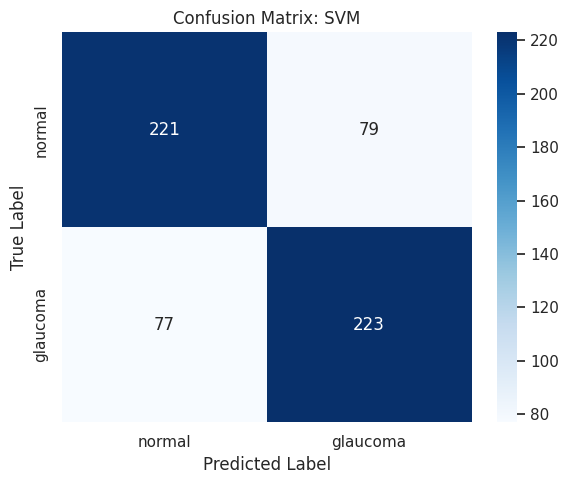

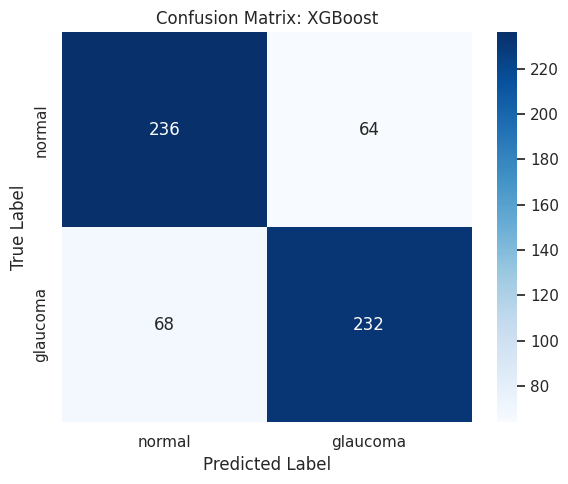

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, model_name, class_names=CLASSES):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()

# Plot Confusion Matrix for SVM
plot_confusion_matrix(y_test, svm_pred, 'SVM')

# Plot Confusion Matrix for XGBoost
plot_confusion_matrix(y_test, xgb_pred, 'XGBoost')

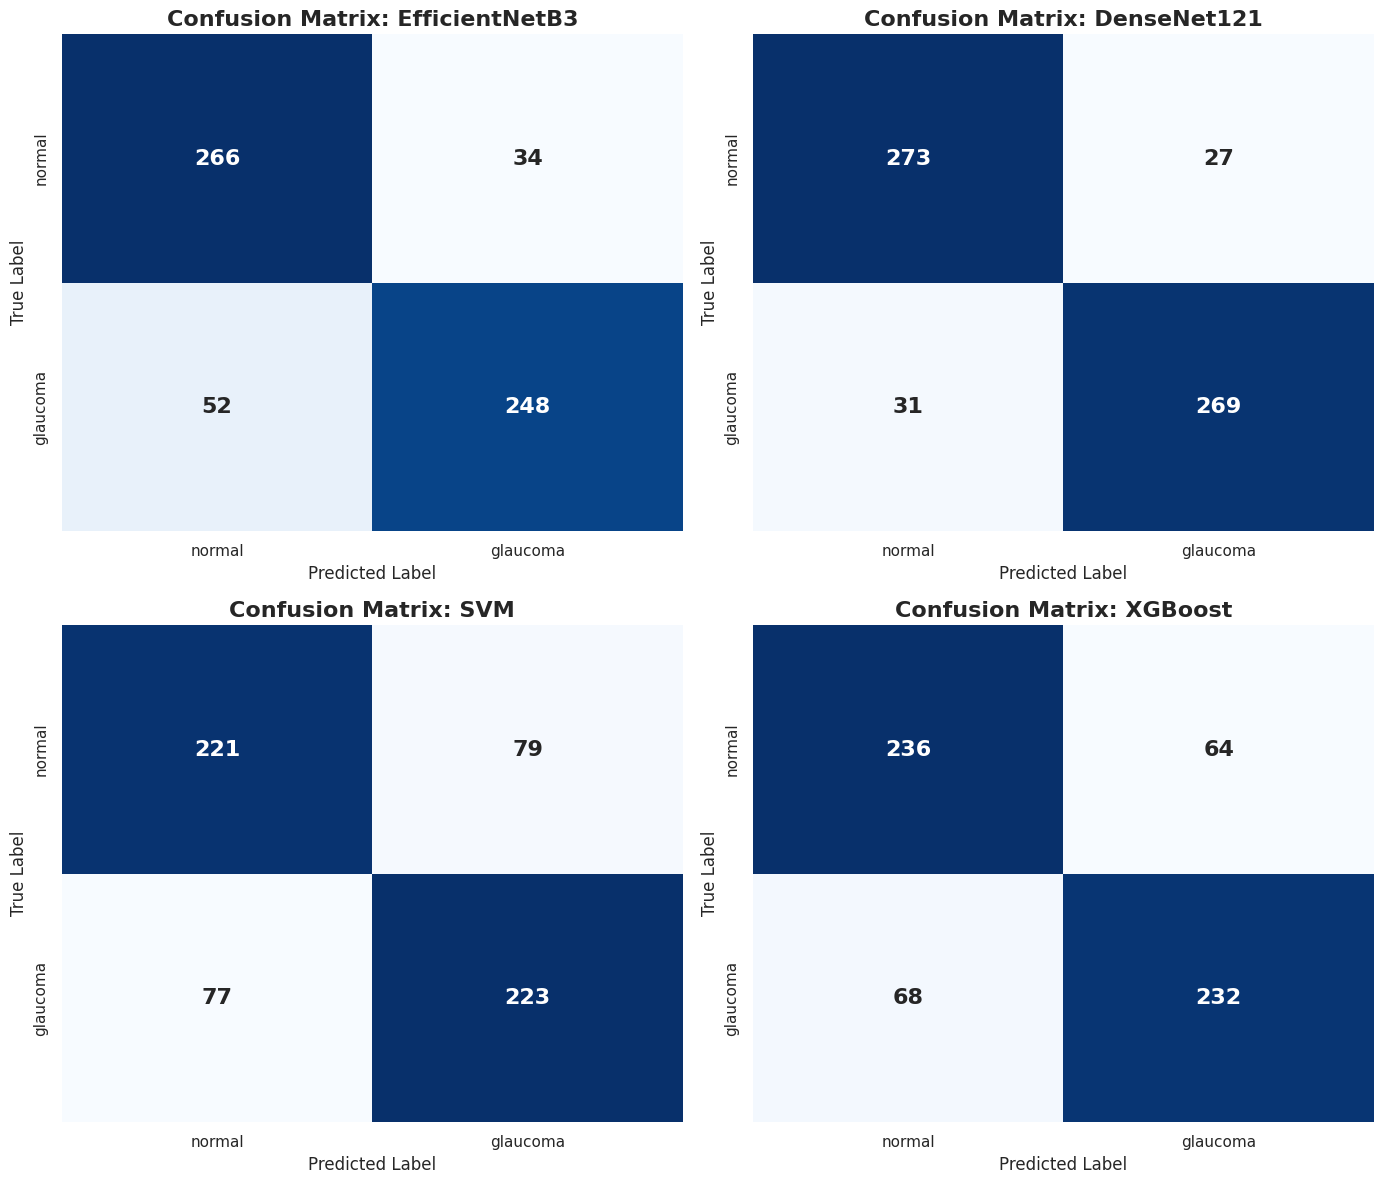

In [33]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def get_dl_preds(model, ds):
    y_true, y_pred = [], []
    for x, y in ds:
        preds = model.predict(x, verbose=0)
        y_true.extend(np.argmax(y, axis=1))
        y_pred.extend(np.argmax(preds, axis=1))
    return np.array(y_true), np.array(y_pred)

# 1. Get predictions for all models
y_true_eff, y_pred_eff = get_dl_preds(model_A, test_ds_A)
y_true_den, y_pred_den = get_dl_preds(model_B, test_ds_B)
# SVM and XGB already have svm_pred and xgb_pred from earlier cells (using y_test)

models_preds = [
    ("EfficientNetB3", y_true_eff, y_pred_eff),
    ("DenseNet121", y_true_den, y_pred_den),
    ("SVM", y_test, svm_pred),
    ("XGBoost", y_test, xgb_pred)
]

# 2. Plotting
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, (name, true, pred) in enumerate(models_preds):
    cm = confusion_matrix(true, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
                annot_kws={"size": 16, "weight": "bold"})
    axes[i].set_title(f"Confusion Matrix: {name}", fontsize=16, fontweight='bold')
    axes[i].set_xlabel("Predicted Label", fontsize=12)
    axes[i].set_ylabel("True Label", fontsize=12)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "all_models_confusion_matrices.png"), dpi=300)
plt.show()